# 03 · Phase 2 evaluation: did seeing the whole patch fix Phase 1's errors? (Sachin)

Phase 1's tuned XGBoost made two kinds of error (notebook 02, section 5):
1. **It missed fire far from the day-t front**: 64% of missed fire pixels were more than 5 km from any day-t fire,
   and recall beyond 5 km was zero.
2. **It raised false alarms around fires that were dying down**: a ≈2 km halo around every burning pixel,
   53% of false positives in patches whose fire shrinks.

This notebook asks whether the Phase 2 networks, which see the whole 64 × 64 km patch, fix them.
Every number is computed with the same code as Phase 1 (`src/eval_utils.py`, taken from notebook 02).

**Inputs** (not made here):
- `reports/preds/{name}.npz` (Phase 1) and `reports/dl/preds/{name}.npz` (Phase 2): `y_true`, `y_prob`, shape (1689, 64, 64),
  test split in `load_split("test")` order.
- `reports/results.csv`, `reports/dl/results_dl.csv`: test metrics; the `threshold` column was chosen on **eval**.
- `reports/dl/checks/seeds.csv`, `ci_events.csv` (Priyanshu), `reports/dl/channel_ablation.csv` (Sushant).
- `models/{name}.pt` for the saliency section, `reports/dl/norm_stats.json` (train-only normalisation).

**Rules (as in Phase 1):** pixels labelled −1 are dropped from every metric; thresholds come from eval, never from test.

**Outputs:** `reports/dl/figures/dl_eval_*.png`, `reports/dl/results_table.md`, `reports/dl/dl_eval_*.csv`.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":       # run from the repo root so `src` imports and relative paths work
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve, roc_auc_score

from src import eval_utils as eu
from src.data import CHANNELS
from src.evaluate import metrics
from src.dl_data import CHANNEL_GROUPS

SEED = 0

# ---- The models of this notebook. When the final models land, change these lists and rerun. ----
PHASE1 = {"persistence": "Persistence", "xgboost": "XGBoost (tuned)", "lightgbm": "LightGBM (tuned)"}
PHASE2 = {"cnn_bce": "CNN (BCE)", "unet_focal": "U-Net depth 3 (focal)", "unet_final_s0": "U-Net final (depth 4, focal)"}
REF_P1, REF_P2 = "xgboost", "unet_final_s0"  # the head-to-head pair of sections 3-8
# models/{name}.pt for saliency with its architecture; the first one found is used
CKPTS = {"unet_final_s0": {"depth": 4, "width": 32}, "unet_focal": {"depth": 3, "width": 32},
         "unet_base": {"depth": 3, "width": 32}}
# -------------------------------------------------------------------------------------------------

DL_DIR, FIGS = Path("reports/dl"), Path("reports/dl/figures")
FIGS.mkdir(parents=True, exist_ok=True)

missing = [m for m in {**PHASE1, **PHASE2} if eu.pred_path(m) is None]
MODELS = {m: lab for m, lab in {**PHASE1, **PHASE2}.items() if m not in missing}
HEAD = [m for m in (REF_P1, REF_P2) if m in MODELS]
print("models with predictions:", list(MODELS))
if missing:
    print("MISSING predictions (skipped):", missing)

# Colours as in Priyanshu's Phase 2 figures; solid = Phase 2 (DL), dashed = Phase 1
BASE_COLORS = {"persistence": "#999999", "xgboost": "#E69F00", "lightgbm": "#CC79A7",
               "cnn_bce": "#009E73", "unet_focal": "#56B4E9", "unet_final_s0": "#0072B2"}
EXTRA = iter(["#D55E00", "#56B4E9", "#F0E442", "#000000"])
COLORS = {m: BASE_COLORS.get(m) or next(EXTRA) for m in MODELS}
STYLE = {m: "-" if m in PHASE2 else "--" for m in MODELS}

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

models with predictions: ['persistence', 'xgboost', 'lightgbm', 'cnn_bce', 'unet_focal', 'unet_final_s0']


In [2]:
results = eu.load_results()               # Phase 1 + Phase 2 test metrics, one row per run
maps = eu.test_maps()                     # labels, day-t fire, wind, elevation, distance to day-t fire
y_map, prev, dist = maps["y"], maps["prev"], maps["dist"]
labelled = y_map != -1
y_flat = y_map[labelled].astype(int)

P = {}
for m in MODELS:
    y_m, P[m] = eu.load_preds(m)
    assert (y_m == y_map).all(), f"{m}: predictions are not in load_split('test') order"
THR = {m: results.loc[m, "threshold"] for m in MODELS}          # chosen on eval
PRED = {m: P[m] >= THR[m] for m in MODELS}

# Consistency check: the files must reproduce the official scores, otherwise they come from another run.
check = pd.DataFrame({m: {"PR AUC (file)": metrics(y_map, P[m])["pr_auc"], "PR AUC (official)": results.loc[m, "pr_auc"],
                          "threshold (eval)": THR[m]} for m in MODELS}).T
check["matches"] = (check["PR AUC (file)"] - check["PR AUC (official)"]).abs() < 5e-4
print(f"test: {len(y_map)} patches, {labelled.sum():,} labelled pixels, fire rate {y_flat.mean():.4f}")
if not check["matches"].all():
    print("WARNING: these prediction files do not reproduce their official PR AUC:", check.index[~check["matches"]].tolist())
check.round(4)

test: 1689 patches, 6,727,699 labelled pixels, fire rate 0.0125


,PR AUC (file),PR AUC (official),threshold (eval),matches
persistence,0.1065,0.1065,0.5000,True
xgboost,0.2565,0.2565,0.9152,True
lightgbm,0.2483,0.2483,0.9166,True
cnn_bce,0.2591,0.2591,0.9281,True
unet_focal,0.2694,0.2694,0.7464,True
unet_final_s0,0.3376,0.3376,0.7490,True


## 1 · Precision-recall and ROC curves: Phase 2 vs Phase 1

As in notebook 02: PR AUC is the main metric (1.25% of labelled pixels burn); dots mark the operating point at the
eval-chosen threshold. **Solid = Phase 2 (DL), dashed = Phase 1.** Persistence outputs only 0/1, so it is one point.

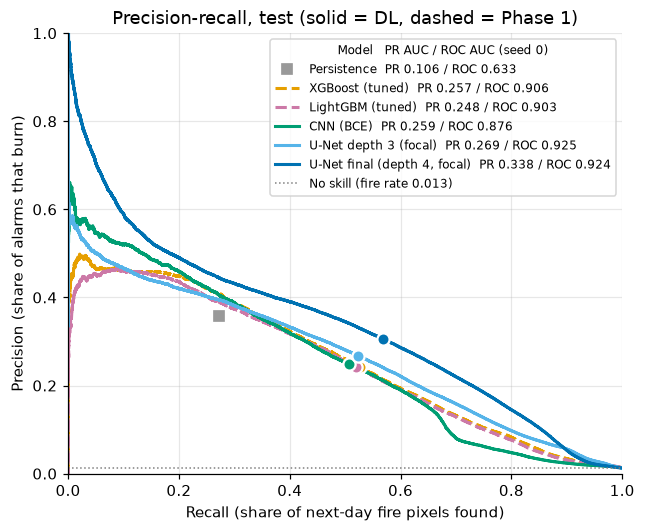

In [3]:
def operating_point(m):
    r = results.loc[m]
    return r.recall, r.precision

fig, ax = plt.subplots(figsize=(6.5, 5.2))
for m, label in MODELS.items():
    r = results.loc[m]
    legend = f"{label}  PR {r.pr_auc:.3f} / ROC {r.roc_auc:.3f}"
    if m == "persistence":
        ax.plot(r.recall, r.precision, "s", ms=9, color=COLORS[m], mec="white", mew=1.5, zorder=6, label=legend)
        continue
    precision, recall, _ = precision_recall_curve(y_flat, P[m][labelled])
    ax.plot(recall, precision, STYLE[m], color=COLORS[m], lw=2, label=legend)
    ax.plot(*operating_point(m), "o", ms=8, color=COLORS[m], mec="white", mew=1.5, zorder=5)
ax.axhline(y_flat.mean(), color="grey", lw=1, ls=":", label=f"No skill (fire rate {y_flat.mean():.3f})")
ax.set(xlabel="Recall (share of next-day fire pixels found)", ylabel="Precision (share of alarms that burn)",
       xlim=(0, 1), ylim=(0, 1), title="Precision-recall, test (solid = DL, dashed = Phase 1)")
ax.legend(fontsize=8, loc="upper right", title="Model   PR AUC / ROC AUC (seed 0)", title_fontsize=8)
fig.savefig(FIGS / "dl_eval_pr_curves.png")
plt.show()

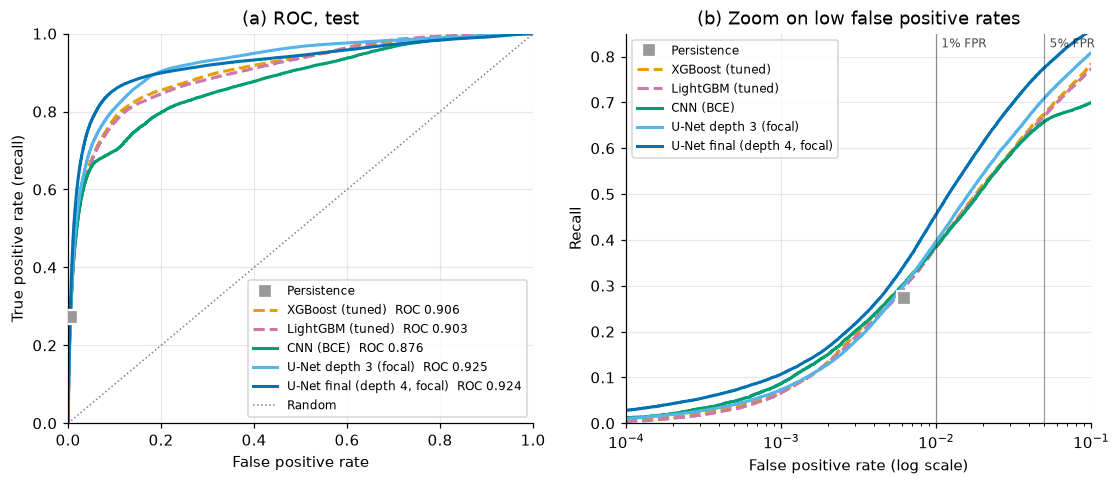

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for m, label in MODELS.items():
    fpr, tpr, _ = roc_curve(y_flat, P[m][labelled])
    if m == "persistence":           # one real operating point; point 0 is the (0, 0) corner
        for ax in axes:
            ax.plot(fpr[1], tpr[1], "s", ms=9, color=COLORS[m], mec="white", mew=1.5, zorder=6, label=label)
        continue
    axes[0].plot(fpr, tpr, STYLE[m], color=COLORS[m], lw=2, label=f"{label}  ROC {results.loc[m, 'roc_auc']:.3f}")
    keep = fpr > 0                    # log axis cannot show FPR = 0
    axes[1].plot(fpr[keep], tpr[keep], STYLE[m], color=COLORS[m], lw=2, label=label)
axes[0].plot([0, 1], [0, 1], color="grey", lw=1, ls=":", label="Random")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", xlim=(0, 1), ylim=(0, 1), title="(a) ROC, test")
axes[0].legend(fontsize=8, loc="lower right")
for x in (0.01, 0.05):
    axes[1].axvline(x, color="black", lw=0.8, alpha=0.4)
    axes[1].text(x * 1.08, 0.82, f"{x:.0%} FPR", fontsize=8, alpha=0.7)
axes[1].set(xscale="log", xlim=(1e-4, 0.1), ylim=(0, 0.85), xlabel="False positive rate (log scale)", ylabel="Recall",
            title="(b) Zoom on low false positive rates")
axes[1].legend(fontsize=8, loc="upper left")
fig.savefig(FIGS / "dl_eval_roc_curves.png")
plt.show()

**Reading the curves**

- **The final U-Net is above every Phase 1 model along the whole PR curve**: PR AUC 0.338 (seed 0) against 0.257 for
  tuned XGBoost and 0.248 for LightGBM. The depth-3 U-Net (0.269) and the CNN (0.259) sit almost on top of XGBoost,
  so the gain comes with depth 4, not with deep learning as such (receptive field, Section `sec:dl_theory_rf`).
- At its eval-chosen threshold the final U-Net is better on both axes at once: precision 0.306 vs 0.243 and recall
  0.567 vs 0.526.
- ROC AUC hardly separates the models (0.906 XGBoost, 0.924 final U-Net, 0.926 depth-3 U-Net). The gain is at low
  false-alarm rates (panel b): recall at 1% FPR 0.455 vs 0.388, at 5% FPR 0.776 vs 0.675, where a fire agency
  would operate.
- Persistence (one point, recall 0.273 at precision 0.357) is below every learned model's curve.

## 2 · Combined results table

Same columns as Phase 1. Networks are not reproducible run to run on a GPU (technical validation), so Phase 2 rows
are **mean ± standard deviation over seeds 0, 1, 2** (`reports/dl/checks/seeds.csv`; for the depth-3 U-Net,
computed here from its three runs); XGBoost is given both as the
committed single run and over 3 seeds, so the main comparison is mean against mean. Other runs are single seed-0 runs.
F1 is at the eval-chosen threshold.

In [5]:
COLS = {"pr_auc": "PR AUC", "roc_auc": "ROC AUC", "f1": "F1", "recall_at_1fpr": "Recall @ 1% FPR",
        "recall_at_5fpr": "Recall @ 5% FPR"}
NAMES = {"persistence": "Persistence", "logreg_raw": "Logistic reg. (raw)", "rf_raw": "Random forest (raw)",
         "xgb_raw": "XGBoost (raw)", "xgboost": "XGBoost (tuned)", "lightgbm": "LightGBM (tuned)",
         "cnn_base": "CNN (BCE, reference run)", "unet_base": "U-Net (BCE, reference run)",
         "unet_bce": "U-Net (BCE)", "unet_bce_dice": "U-Net (BCE + Dice)",
         "unet_d4_w32": "U-Net depth 4 (BCE)", "unet_hybrid_d4": "Hybrid U-Net depth 4 (+ XGBoost channel)",
         "ens_base_xgb_weighted": "Ensemble U-Net depth 3 + XGBoost (weighted)",
         "unet_final": "U-Net final (depth 4, focal)", **PHASE1, **PHASE2}
# Seed groups: taken from seeds.csv when Priyanshu lists them, otherwise mean ± std (sample std, as in seeds.csv)
# computed here from the per-run rows of runs.csv / results_dl.csv
SEED_RUNS = {"unet_final": ["unet_final_s0", "unet_final_s1", "unet_final_s2"],
             "unet_focal": ["unet_focal", "unet_focal_s1", "unet_focal_s2"]}
seeds = pd.read_csv(DL_DIR / "checks" / "seeds.csv").set_index("model")

rows = []
for m in ["persistence", "logreg_raw", "rf_raw", "xgb_raw", "xgboost", "lightgbm"]:
    rows.append({"Phase": "1", "Model": NAMES[m], "Runs": "1", **{v: f"{results.loc[m, k]:.3f}" for k, v in COLS.items()}})
for m in seeds.index:                                       # mean ± std over seeds
    s = seeds.loc[m]
    rows.append({"Phase": "1" if m in PHASE1 else "2", "Model": NAMES.get(m, m), "Runs": f"{int(s.n_seeds)} seeds",
                 **{v: f"{s[k + '_mean']:.3f} ± {s[k + '_std']:.3f}" for k, v in COLS.items()}})
for g, runs in SEED_RUNS.items():
    if g in seeds.index:
        continue
    r = results.loc[runs, list(COLS)]
    rows.append({"Phase": "2", "Model": NAMES[g], "Runs": f"{len(runs)} seeds",
                 **{v: f"{r[k].mean():.3f} ± {r[k].std():.3f}" for k, v in COLS.items()}})
single_dl = [m for m in ["cnn_base", "unet_base", "unet_bce", "unet_bce_dice", "unet_d4_w32", "unet_hybrid_d4",
                         "ens_base_xgb_weighted"] if m in results.index]
for m in single_dl:
    rows.append({"Phase": "2", "Model": NAMES[m], "Runs": "1 (seed 0)", **{v: f"{results.loc[m, k]:.3f}" for k, v in COLS.items()}})
table = pd.DataFrame(rows).sort_values("Phase", kind="stable").set_index("Model")
table

,Phase,Runs,PR AUC,ROC AUC,F1,Recall @ 1% FPR,Recall @ 5% FPR
Model,,,,,,,
Persistence,1,1,0.106,0.633,0.309,0.273,0.273
Logistic reg. (raw),1,1,0.146,0.798,0.312,0.281,0.319
Random forest (raw),1,1,0.157,0.816,0.312,0.279,0.362
XGBoost (raw),1,1,0.145,0.795,0.292,0.267,0.375
XGBoost (tuned),1,1,0.257,0.906,0.332,0.388,0.675
LightGBM (tuned),1,1,0.248,0.903,0.331,0.384,0.671
XGBoost (tuned),1,3 seeds,0.255 ± 0.002,0.905 ± 0.001,0.330 ± 0.000,0.388 ± 0.001,0.673 ± 0.001
"U-Net final (depth 4, focal)",2,3 seeds,0.344 ± 0.007,0.934 ± 0.009,0.399 ± 0.003,0.459 ± 0.003,0.783 ± 0.006
CNN (BCE),2,3 seeds,0.249 ± 0.010,0.878 ± 0.011,0.335 ± 0.008,0.378 ± 0.009,0.653 ± 0.006


In [6]:
md_main = "\n".join([
    "# Phase 1 vs Phase 2 results (test split, 1,689 patches, 6.73M labelled pixels, 1.25% fire)",
    "",
    "Mean ± standard deviation (sample std) over seeds 0-2 where several runs exist (`reports/dl/checks/seeds.csv`; depth-3 U-Net from its three runs); other rows are single runs. "
    "F1 at the threshold chosen on the eval split. XGBoost over 3 seeds is Priyanshu's refit with the committed hyperparameters.",
    "",
    eu.to_markdown(table, bold_max=False),
    "",
])
print(md_main)

# Phase 1 vs Phase 2 results (test split, 1,689 patches, 6.73M labelled pixels, 1.25% fire)

Mean ± standard deviation (sample std) over seeds 0-2 where several runs exist (`reports/dl/checks/seeds.csv`; depth-3 U-Net from its three runs); other rows are single runs. F1 at the threshold chosen on the eval split. XGBoost over 3 seeds is Priyanshu's refit with the committed hyperparameters.

| Model | Phase | Runs | PR AUC | ROC AUC | F1 | Recall @ 1% FPR | Recall @ 5% FPR |
|---|---:|---:|---:|---:|---:|---:|---:|
| Persistence | 1 | 1 | 0.106 | 0.633 | 0.309 | 0.273 | 0.273 |
| Logistic reg. (raw) | 1 | 1 | 0.146 | 0.798 | 0.312 | 0.281 | 0.319 |
| Random forest (raw) | 1 | 1 | 0.157 | 0.816 | 0.312 | 0.279 | 0.362 |
| XGBoost (raw) | 1 | 1 | 0.145 | 0.795 | 0.292 | 0.267 | 0.375 |
| XGBoost (tuned) | 1 | 1 | 0.257 | 0.906 | 0.332 | 0.388 | 0.675 |
| LightGBM (tuned) | 1 | 1 | 0.248 | 0.903 | 0.331 | 0.384 | 0.671 |
| XGBoost (tuned) | 1 | 3 seeds | 0.255 ± 0.002 | 0.905 ± 0.001 | 0.33

**Reading the table**

- Over three seeds the final U-Net reaches **0.344 ± 0.007** against **0.255 ± 0.002** for XGBoost (same refit
  over seeds): +0.089, more than ten times the seed spread. It leads on every column: F1 0.398 vs 0.330, recall at
  1% FPR 0.459 vs 0.388, at 5% FPR 0.783 vs 0.673.
- The depth-3 U-Net (0.275 ± 0.008) and the CNN (0.249 ± 0.010) are within about 0.02 of XGBoost. Depth is the step
  that matters: the depth-4 U-Net trained with plain weighted BCE (0.337, one seed) is as good as the focal one.
- Adding XGBoost does not help once the U-Net has depth 4: the hybrid with the XGBoost map as a 13th channel scores
  0.335, and an eval-tuned ensemble gives XGBoost zero weight (Sushant's `hybrid_ensemble_summary.md`).

## 3 · Probability maps

**(a)** The same 10 random test patches as Phase 1 (seed 0, patches with next-day fire). Columns: fire on day t,
true fire on day t+1, then each model's probability; the black line is the model's eval-chosen threshold and the
arrow shows where the wind blows. The two networks' scores are on different scales (focal loss gives flatter scores,
threshold ≈0.75 instead of ≈0.92), so compare shapes and the threshold line rather than colours.

**(b)** Phase 1's 5 worst false-positive and 5 worst false-negative patches (notebook 02, section 5), with the
thresholded outcome of each model: does the U-Net fix them?

10 random patches (same as Phase 1): [33, 69, 120, 290, 443, 515, 856, 1071, 1369, 1432]


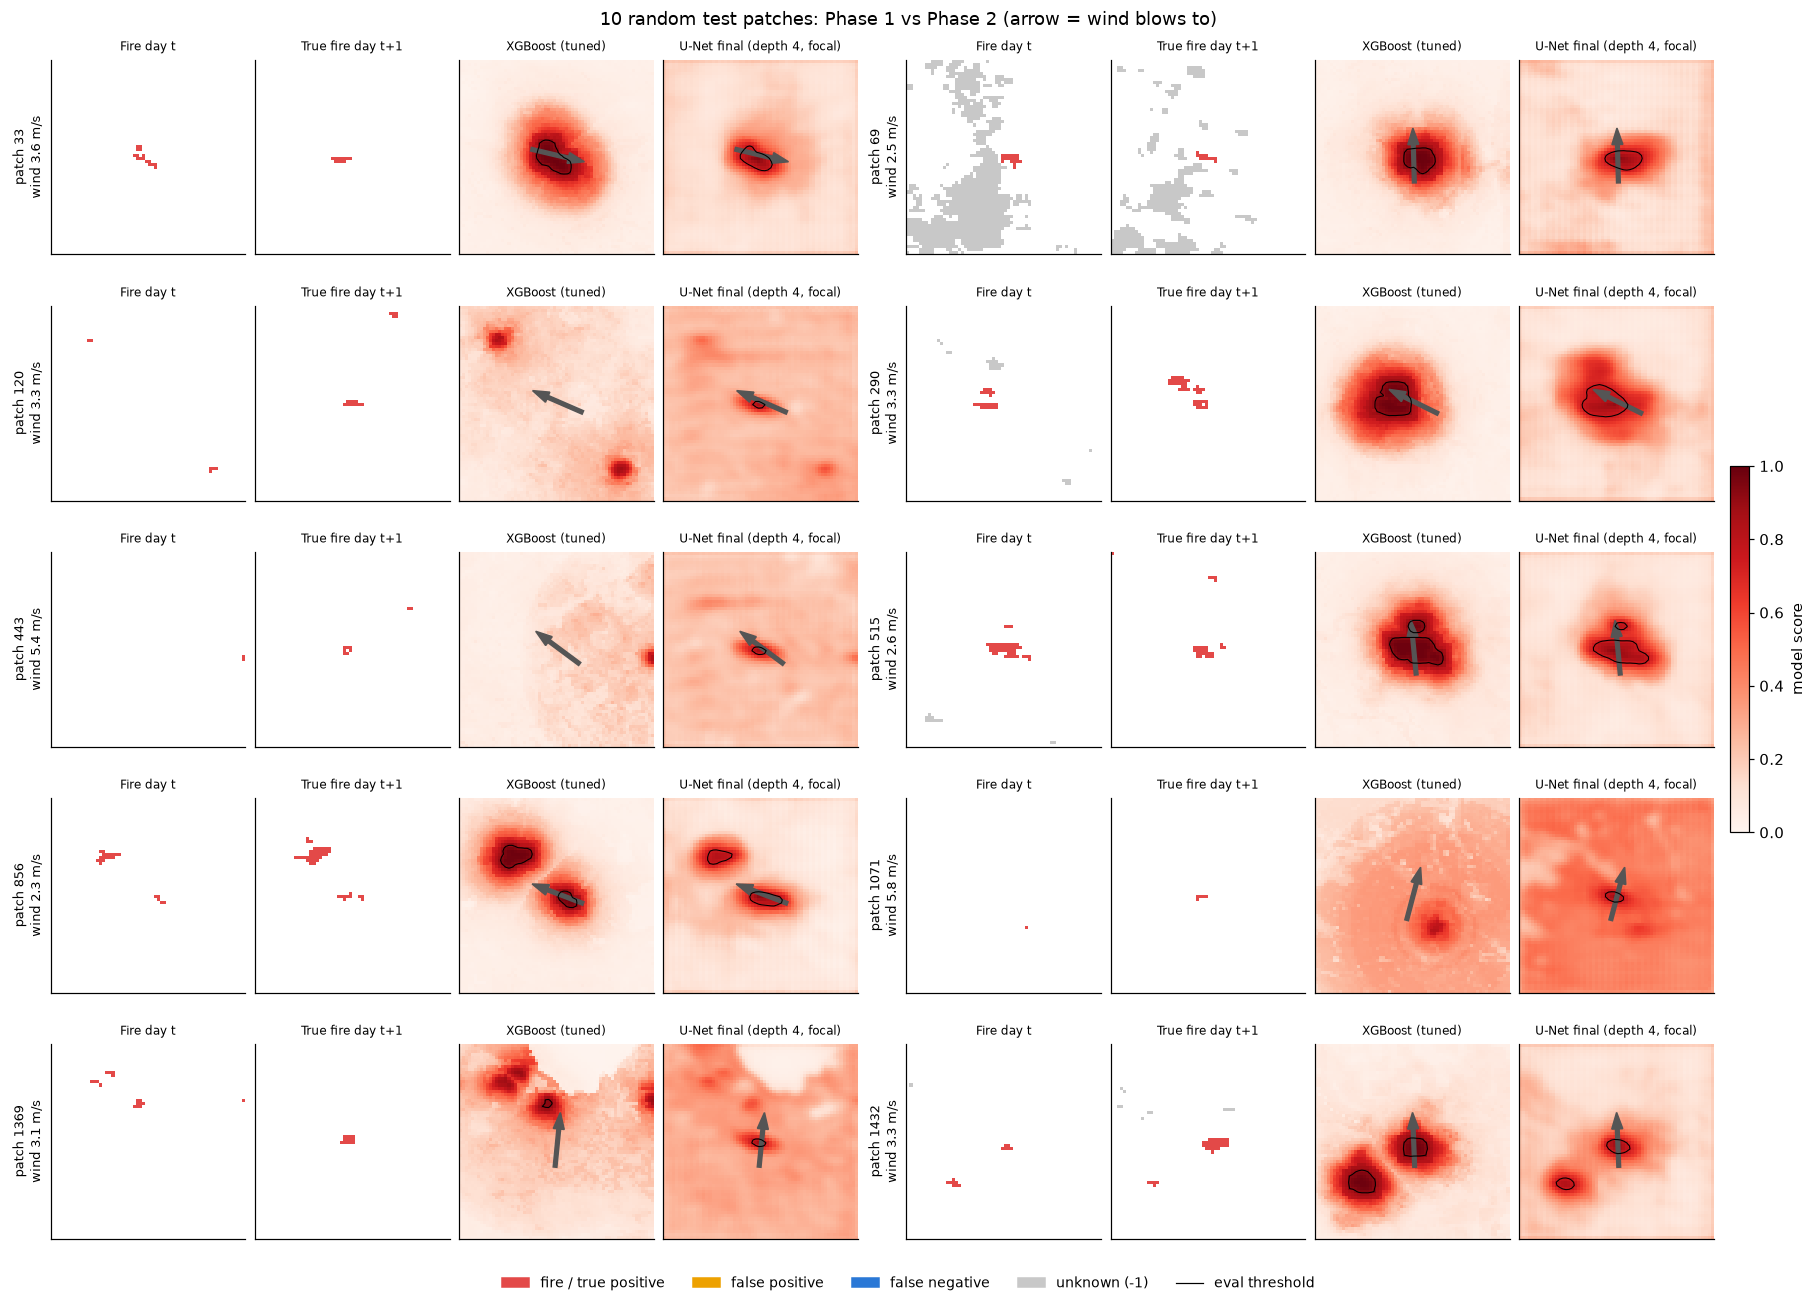

,fire_t,fire_t+1,FP xgboost,FN xgboost,FP unet_final_s0,FN unet_final_s0
patch,,,,,,
33,16,11,69,1,42,1
69,19,12,57,2,48,2
120,6,16,0,16,2,9
290,23,43,83,15,90,19
443,2,9,0,9,5,5
515,48,29,114,5,88,5
856,22,47,44,16,38,21
1071,1,5,0,5,10,2
1369,17,13,8,13,3,7


In [7]:
MASK_CMAP, OUT_CMAP = ListedColormap(eu.MASK_COLORS), ListedColormap(eu.OUT_COLORS)
th_map, vs_map = maps["th"], maps["vs"]


def plot_compare(idx, path, title, outcomes=False, per_row=2):
    """Per patch: day t | day t+1 | probability (+ outcome) of each model in HEAD."""
    heads = ["Fire day t", "True fire day t+1"]
    for m in HEAD:
        heads += [f"{MODELS[m]}"] + ([f"{MODELS[m]}: outcome"] if outcomes else [])
    k = len(heads)
    n_rows = int(np.ceil(len(idx) / per_row))
    fig, axes = plt.subplots(n_rows, k * per_row, figsize=(2.05 * k * per_row, 2.15 * n_rows + 1.0),
                             squeeze=False, layout="constrained")
    for j, ax in enumerate(axes.flat):
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if (j // (k * per_row)) * per_row + (j % (k * per_row)) // k >= len(idx):
            ax.axis("off")
    for n, i in enumerate(idx):
        a = axes[n // per_row, k * (n % per_row): k * (n % per_row) + k]
        show = dict(interpolation="nearest", origin="lower")
        a[0].imshow(prev[i] + 1, cmap=MASK_CMAP, vmin=0, vmax=2, **show)
        a[1].imshow(y_map[i] + 1, cmap=MASK_CMAP, vmin=0, vmax=2, **show)
        col = 2
        for m in HEAD:
            im = a[col].imshow(P[m][i], cmap="Reds", vmin=0, vmax=1, **show)
            if (P[m][i] >= THR[m]).any() and (P[m][i] < THR[m]).any():
                a[col].contour(P[m][i], levels=[THR[m]], colors="black", linewidths=0.7)
            eu.wind_arrow(a[col], th_map[i], color="#555555")
            col += 1
            if outcomes:
                a[col].imshow(eu.outcome_map(y_map[i], PRED[m][i]), cmap=OUT_CMAP, vmin=0, vmax=4, **show)
                c = eu.outcome_counts(y_map[i:i + 1], PRED[m][i:i + 1])
                a[col].set_xlabel(f"FP {c['fp'][0]}  FN {c['fn'][0]}", fontsize=8)
                col += 1
        for h, ax in zip(heads, a):
            ax.set_title(h, fontsize=8)
        a[0].set_ylabel(f"patch {i}\nwind {vs_map[i].mean():.1f} m/s", fontsize=8.5)
    fig.suptitle(title, fontsize=12)
    handles = [Patch(color=eu.FIRE, label="fire / true positive"), Patch(color=eu.FP_C, label="false positive"),
               Patch(color=eu.FN_C, label="false negative"), Patch(color=eu.GREY, label="unknown (-1)"),
               Line2D([], [], color="black", lw=0.8, label="eval threshold")]
    fig.legend(handles=handles, loc="outside lower center", ncol=5, fontsize=9, frameon=False)
    fig.colorbar(im, ax=axes, shrink=min(0.5, 3 / len(idx)), pad=0.01, label="model score")
    fig.savefig(path)
    plt.show()


def patch_stats(idx):
    rows = []
    for i in idx:
        row = {"patch": i, "fire_t": int((prev[i] == 1).sum()), "fire_t+1": int((y_map[i] == 1).sum())}
        for m in HEAD:
            c = eu.outcome_counts(y_map[i:i + 1], PRED[m][i:i + 1])
            row |= {f"FP {m}": int(c["fp"][0]), f"FN {m}": int(c["fn"][0])}
        rows.append(row)
    return pd.DataFrame(rows).set_index("patch")


rng = np.random.default_rng(SEED)
fire_patches = np.flatnonzero((y_map == 1).any(axis=(1, 2)))
chosen = np.sort(rng.choice(fire_patches, size=10, replace=False))
print("10 random patches (same as Phase 1):", chosen.tolist())
plot_compare(chosen, FIGS / "dl_eval_prob_maps.png", "10 random test patches: Phase 1 vs Phase 2 (arrow = wind blows to)")
patch_stats(chosen)

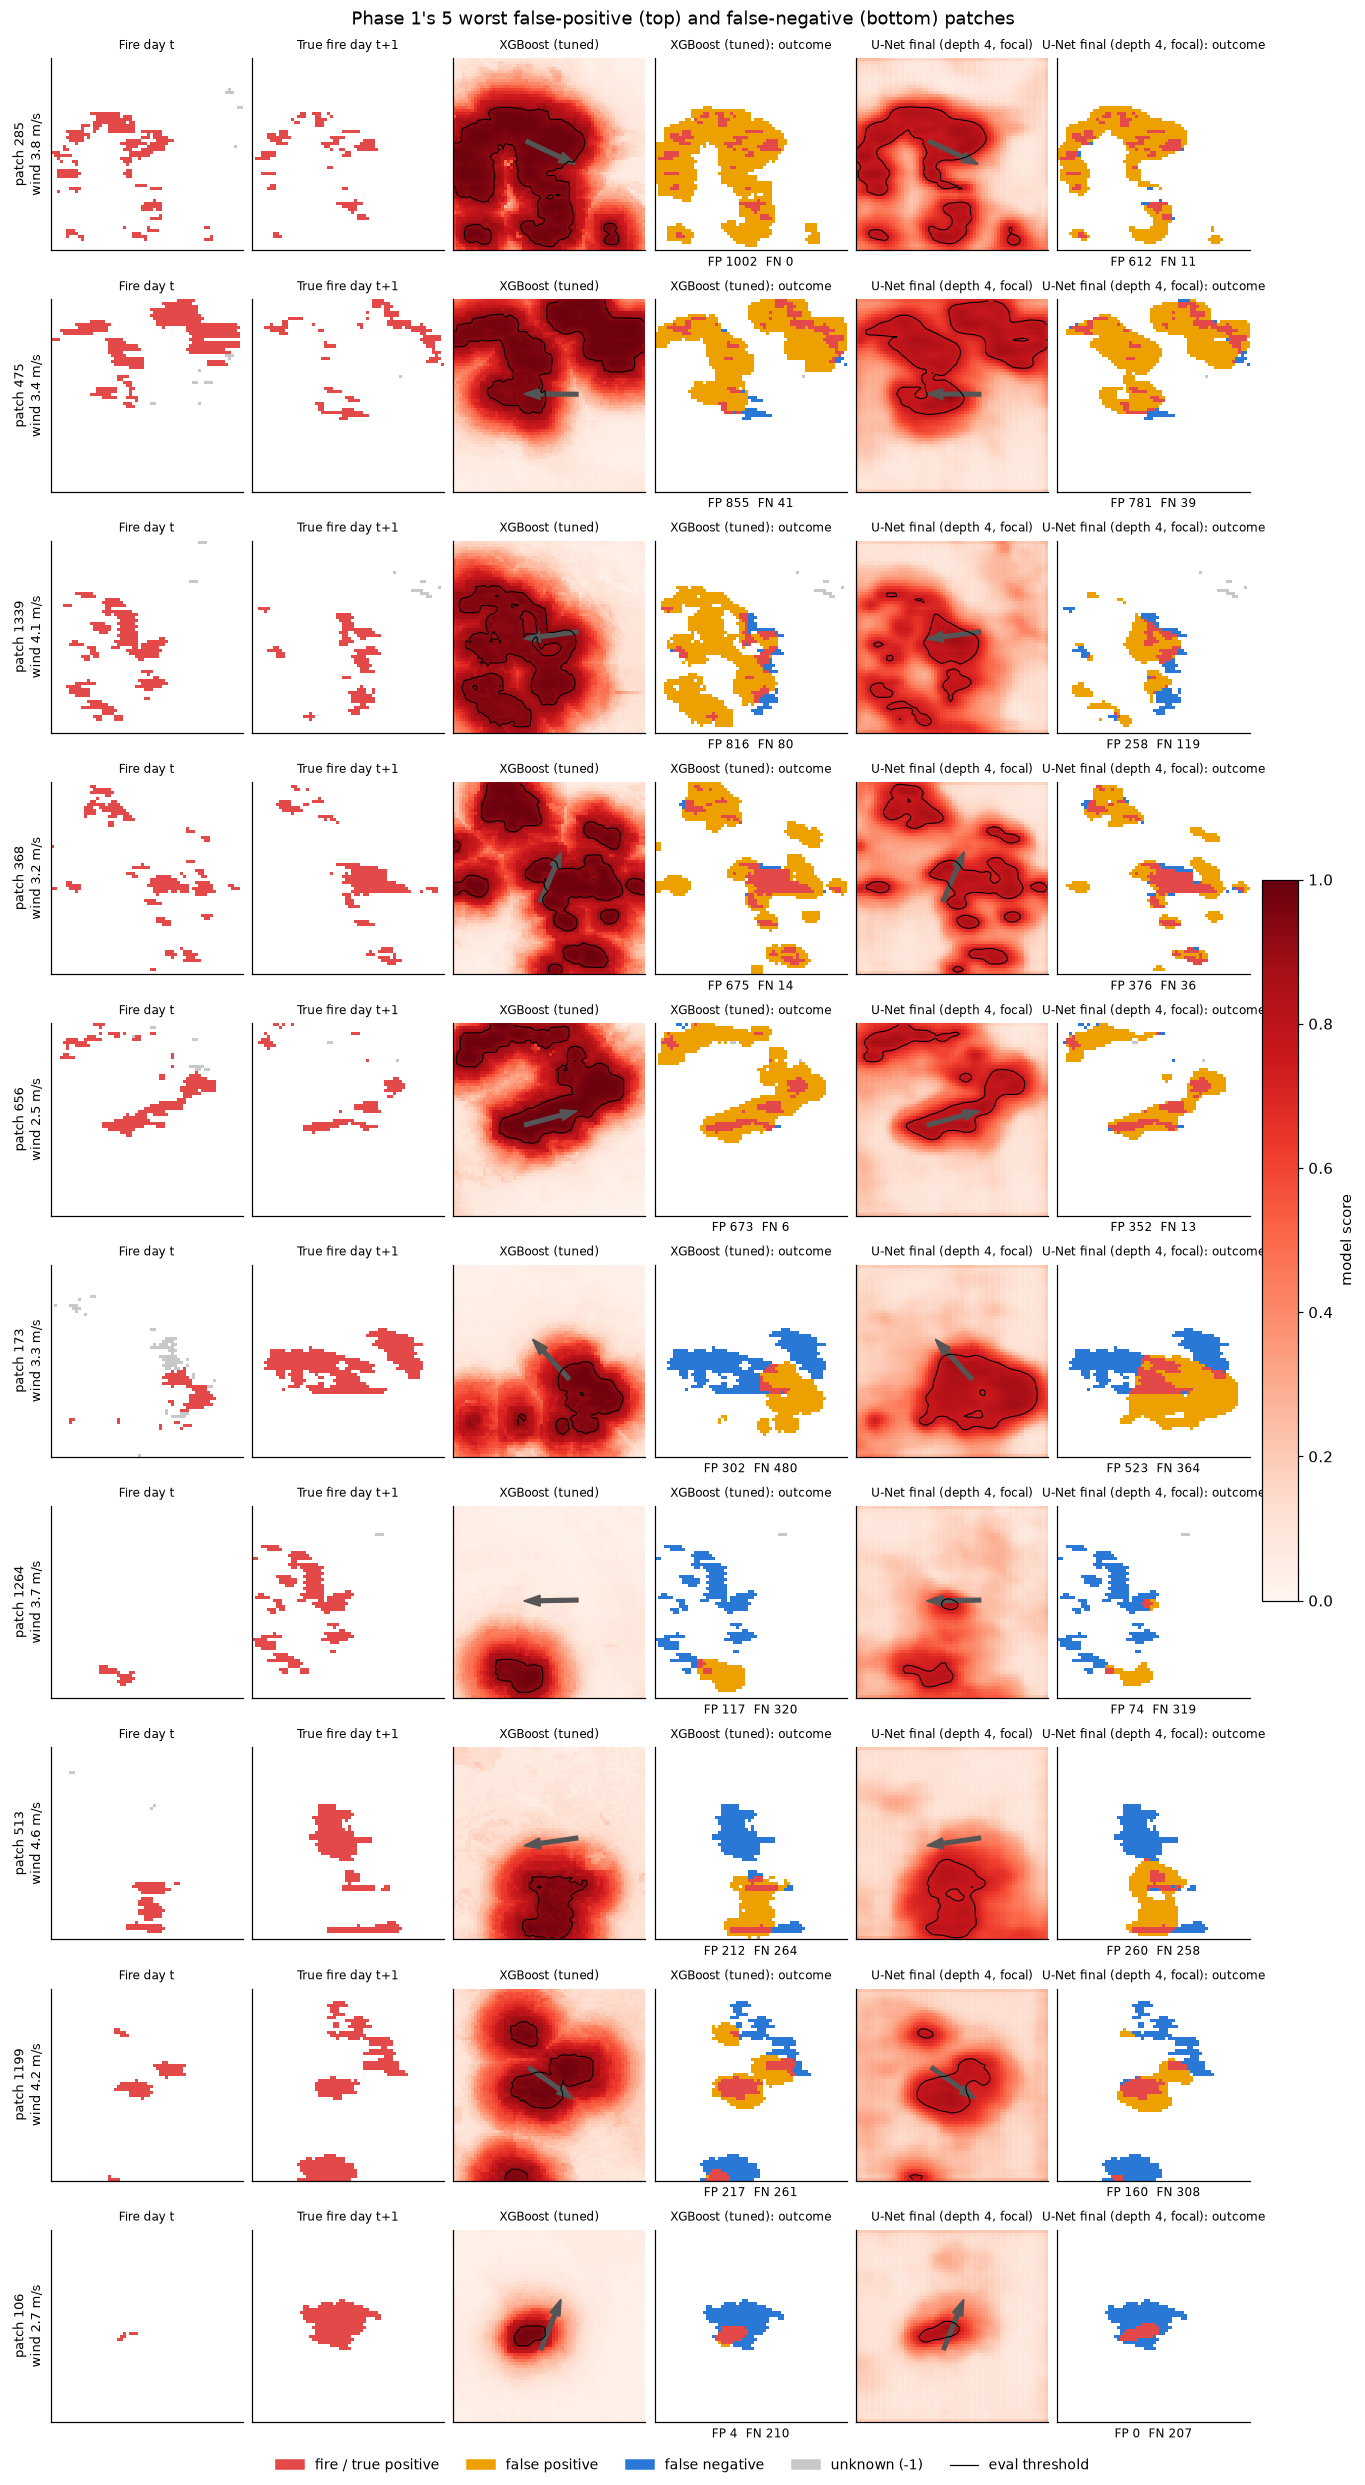

,Phase 1 case,fire_t,fire_t+1,FP xgboost,FN xgboost,FP unet_final_s0,FN unet_final_s0
patch,,,,,,,
285,worst FP,316,162,1002,0,612,11
475,worst FP,468,193,855,41,781,39
1339,worst FP,334,189,816,80,258,119
368,worst FP,277,259,675,14,376,36
656,worst FP,255,136,673,6,352,13
173,worst FN,116,515,302,480,523,364
1264,worst FN,35,333,117,320,74,319
513,worst FN,121,324,212,264,260,258
1199,worst FN,104,406,217,261,160,308


In [8]:
# Phase 1's worst patches (notebook 02, section 5: most FP / FN pixels for tuned XGBoost, one patch per fire)
P1_WORST_FP = [285, 475, 1339, 368, 656]
P1_WORST_FN = [173, 1264, 513, 1199, 106]
plot_compare(P1_WORST_FP + P1_WORST_FN, FIGS / "dl_eval_worst_cases.png",
             "Phase 1's 5 worst false-positive (top) and false-negative (bottom) patches", outcomes=True, per_row=1)
worst = patch_stats(P1_WORST_FP + P1_WORST_FN)
worst.insert(0, "Phase 1 case", ["worst FP"] * 5 + ["worst FN"] * 5)
worst

**Reading the maps**

*10 random patches.* The XGBoost map is a round halo of ≈2 km around every burning pixel; the U-Net map is tighter
and follows the shape of the fire. On small fires that stay put it raises fewer false alarms (patch 33: 69 → 42
false-positive pixels, 69: 57 → 48, 1432: 72 → 21) and it finds some fire XGBoost misses completely (120: 16 → 9
missed pixels, 1369: 13 → 7). On growing fires it is not uniformly better (290: 83 → 90 false positives).

*Phase 1's worst cases.* False alarms around large dying fires drop clearly in four of the five worst patches
(285: 1,002 → 612, 1339: 816 → 258, 368: 675 → 376, 656: 673 → 352), not in 475 (855 → 781). The worst misses are
**not** fixed: patches 1264, 513 and 106 lose the same 207-320 pixels as before, 1199 gets worse (261 → 308), and
173 improves only partly (480 → 364). These are 15-40 km jumps and a fire growing from 8 to 260 pixels in a day,
for which day-t inputs give little warning; section 4 shows that the far-field gain is real on average, but it
does not reach the most extreme cases.

## 4 · Recall by distance from the fire front (the headline result)

Same bands and method as `eval_recall_by_distance.png`: every next-day fire pixel is put in a band by its distance to
the nearest day-t fire pixel (recomputed from `test.npz` exactly as `dist_to_fire` in `src/features.py`), and recall is
the share found at the eval-chosen threshold.

Recall at a threshold depends on where the threshold sits, so panel (b) adds a threshold-free check: PR AUC
computed **within** each band (all labelled pixels of the band, fire and no fire). A model with no skill in a band
scores the band's fire rate (grey).

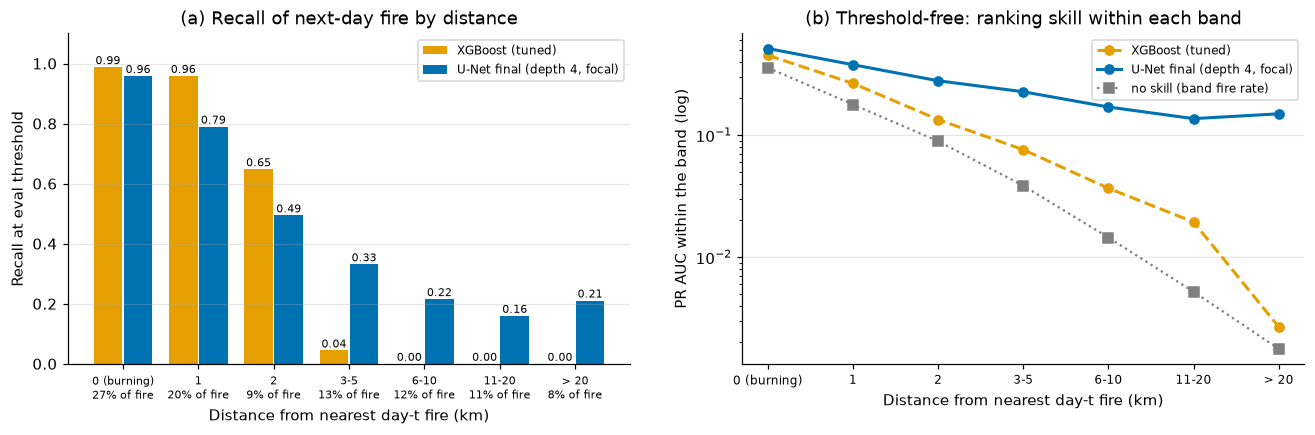

xgboost                          unet_final_s0  \
            fire pixels share of all fire recall   fire pixels   
band                                                             
0 (burning)       23003             0.273  0.988         23003   
1                 16916             0.201  0.959         16916   
2                  7675             0.091  0.648          7675   
3-5               11024             0.131  0.044         11024   
6-10              10041             0.119  0.000         10041   
11-20              8968             0.106  0.000          8968   
> 20               6704             0.079  0.000          6704   

                                      
            share of all fire recall  
band                                  
0 (burning)             0.273  0.958  
1                       0.201  0.790  
2                       0.091  0.494  
3-5                     0.131  0.331  
6-10                    0.119  0.215  
11-20                   0.106  0.160  
> 20                    0.079  0.211

,xgboost,unet_final_s0,fire rate (no skill)
0 (burning),0.4518,0.5136,0.3572
1,0.2659,0.3783,0.1783
2,0.1343,0.2794,0.0893
3-5,0.0761,0.2271,0.0385
6-10,0.0367,0.1702,0.0145
11-20,0.0194,0.1367,0.0052
> 20,0.0027,0.1497,0.0018


,recall (all fire),missed fire pixels,share of missed > 5 km,recall 3-5 km,recall > 5 km
XGBoost (tuned),0.527,39922.0,0.644,0.044,0.000
"U-Net final (depth 4, focal)",0.568,36468.0,0.568,0.331,0.195
Phase 1 reference (notebook 02),0.526,39922.0,0.644,0.044,0.000


In [9]:
rbd = pd.concat({m: eu.recall_by_distance(y_map, PRED[m], dist) for m in HEAD}, axis=1)

band = pd.cut(dist[labelled], eu.DIST_BINS, labels=eu.DIST_NAMES, include_lowest=True)
band_auc = {}
for m in HEAD:
    p_lab = P[m][labelled]
    band_auc[m] = {b: (average_precision_score(y_flat[band == b], p_lab[band == b])
                       if 0 < y_flat[band == b].sum() < (band == b).sum() else np.nan) for b in eu.DIST_NAMES}
band_auc = pd.DataFrame(band_auc)
band_auc["fire rate (no skill)"] = [y_flat[band == b].mean() for b in eu.DIST_NAMES]

fig, axes = plt.subplots(1, 2, figsize=(14.5, 3.9))
x, w = np.arange(len(eu.DIST_NAMES)), 0.8 / len(HEAD)
share = rbd[HEAD[0]]["share of all fire"]
for k, m in enumerate(HEAD):
    r = rbd[m]["recall"].to_numpy()
    axes[0].bar(x + (k - (len(HEAD) - 1) / 2) * w, r, w * 0.95, color=COLORS[m], label=MODELS[m])
    for xi, ri in zip(x, r):
        axes[0].text(xi + (k - (len(HEAD) - 1) / 2) * w, ri + 0.01, f"{ri:.2f}", ha="center", fontsize=7)
axes[0].set_xticks(x, [f"{n}\n{s:.0%} of fire" for n, s in zip(eu.DIST_NAMES, share)], fontsize=7.5)
axes[0].set(xlabel="Distance from nearest day-t fire (km)", ylabel="Recall at eval threshold", ylim=(0, 1.1),
            title="(a) Recall of next-day fire by distance")
axes[0].legend(fontsize=8)
for k, m in enumerate(HEAD):
    axes[1].plot(x, band_auc[m], marker="o", color=COLORS[m], lw=2, ls=STYLE[m], label=MODELS[m])
axes[1].plot(x, band_auc["fire rate (no skill)"], "s:", color="grey", label="no skill (band fire rate)")
axes[1].set_xticks(x, eu.DIST_NAMES, fontsize=8)
axes[1].set(yscale="log", xlabel="Distance from nearest day-t fire (km)", ylabel="PR AUC within the band (log)",
            title="(b) Threshold-free: ranking skill within each band")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.savefig(FIGS / "dl_eval_recall_by_distance.png")
plt.show()

far = pd.DataFrame({MODELS[m]: {
    "recall (all fire)": PRED[m][y_map == 1].mean(),
    "missed fire pixels": int(((y_map == 1) & ~PRED[m]).sum()),
    "share of missed > 5 km": (dist[(y_map == 1) & ~PRED[m]] > 5).mean(),
    "recall 3-5 km": rbd[m].loc["3-5", "recall"],
    "recall > 5 km": PRED[m][(y_map == 1) & (dist > 5)].mean(),
} for m in HEAD}).T
far.loc["Phase 1 reference (notebook 02)"] = [0.526, 39922, 0.644, 0.044, 0.0]
rbd.to_csv(DL_DIR / "dl_eval_recall_by_distance.csv")
display(rbd.round(3), band_auc.round(4))
far.round(3)

**Reading the distance results**

- **This is the main Phase 2 result.** XGBoost finds no fire beyond 5 km (recall 0.000 in every band from 6 km on).
  The final U-Net finds 21.5% at 6-10 km, 16.0% at 11-20 km and 21.1% beyond 20 km, and 33.1% at 3-5 km against 4.4%.
  Its share of missed pixels lying beyond 5 km falls from 64.4% (Phase 1) to 56.8%.
- It pays for this near the fire at its own threshold: recall at 1 km 0.79 vs 0.96, at 2 km 0.49 vs 0.65, with
  higher overall recall (0.568 vs 0.527). The threshold-free panel (b) shows this is a threshold effect, not lost
  skill: within **every** band the U-Net ranks pixels better, by 1.4× at 1 km and 3× at 3-5 km, rising to 4.6×
  at 6-10 km and 7× at 11-20 km. Beyond 20 km XGBoost is at no skill (0.003 vs 0.002) and the U-Net at 0.150.
- Fire 3 km or more from the front is 43% of all next-day fire, so this is where the gain in PR AUC comes from.

### 4b · Is the skill far from the front real?

Fire more than 5 km from any day-t fire is the hardest case, so any skill there is checked against four alternative
explanations before it is reported:
1. **Memorised locations.** 503 test patches cover exactly the same place as a training patch (same elevation map,
   the rule of the technical validation). Far-field skill is scored separately on new and seen locations.
2. **Fire hidden under cloud.** `dist` counts only visible fire, so pixels near day-t unknown (−1) pixels may be
   next to a hidden front. The far region below excludes pixels within 5 km of an unknown day-t pixel.
3. **Patch-level shortcut.** A model could raise every pixel of an active patch without locating anything. The
   within-patch ROC AUC ranks far pixels inside each patch only, so that shortcut scores 0.5.
4. **One leaky input** is tested in section 7 by blanking each channel group for the far region.

In [10]:
from scipy.ndimage import distance_transform_edt
from src.data import DATA_DIR, read_tfrecord, parse_example

# 1. seen locations: test elevation map identical to a training one (streams elevation only, no train.npz needed)
train_elev = {parse_example(r)["elevation"].astype(np.float32).tobytes()
              for f in sorted(DATA_DIR.glob("next_day_wildfire_spread_train_*.tfrecord")) for r in read_tfrecord(f)}
seen = np.array([e.astype(np.float32).ravel().tobytes() in train_elev for e in maps["elev"]])
print(f"seen test locations: {seen.sum()} of {len(seen)}")

# 2. distance to an unknown (-1) day-t pixel; the far region excludes pixels near one
unknown = prev == -1
d_unknown = np.full(prev.shape, 999.0, np.float32)
for i in np.flatnonzero(unknown.any(axis=(1, 2))):
    d_unknown[i] = distance_transform_edt(~unknown[i])
far_clear = (dist > 5) & (d_unknown > 5) & labelled
fire_far = (y_map == 1) & (dist > 5)
print(f"next-day fire > 5 km from visible fire: {fire_far.sum():,} px, "
      f"of which within 5 km of an unknown day-t pixel: {(d_unknown[fire_far] <= 5).mean():.1%}")

# 3. within-patch ranking of far pixels (patches with both fire and no fire in the far region)
both = ((far_clear & (y_map == 1)).sum(axis=(1, 2)) > 0) & ((far_clear & (y_map == 0)).sum(axis=(1, 2)) > 0)

far_check = {}
for m in [m for m in MODELS if m != "persistence"]:
    row = {}
    for grp, sel in (("new", ~seen), ("seen", seen)):
        S = far_clear & sel[:, None, None]
        row[f"PR AUC far, {grp} locations"] = average_precision_score(y_map[S] == 1, P[m][S])
        row[f"no skill, {grp}"] = (y_map[S] == 1).mean()
    row["recall far (no cloud nearby)"] = PRED[m][far_clear & (y_map == 1)].mean()
    w = [roc_auc_score(y_map[i][far_clear[i]] == 1, P[m][i][far_clear[i]]) for i in np.flatnonzero(both)]
    row["within-patch ROC AUC, median"] = np.median(w)
    row["patches with within-patch AUC > 0.9"] = np.mean(np.array(w) > 0.9)
    far_check[MODELS[m]] = row
far_check = pd.DataFrame(far_check)
far_check.to_csv(DL_DIR / "dl_eval_far_field_checks.csv")
print(f"far region: {far_clear.sum():,} labelled px; within-patch AUC over {both.sum()} patches")
far_check.round(4)

seen test locations: 503 of 1689
next-day fire > 5 km from visible fire: 25,713 px, of which within 5 km of an unknown day-t pixel: 8.6%


far region: 5,870,013 labelled px; within-patch AUC over 988 patches


,XGBoost (tuned),LightGBM (tuned),CNN (BCE),U-Net depth 3 (focal),"U-Net final (depth 4, focal)"
"PR AUC far, new locations",0.0240,0.0210,0.0092,0.0375,0.1793
"no skill, new",0.0051,0.0051,0.0051,0.0051,0.0051
"PR AUC far, seen locations",0.0083,0.0093,0.0021,0.0466,0.0658
"no skill, seen",0.0014,0.0014,0.0014,0.0014,0.0014
recall far (no cloud nearby),0.0000,0.0005,0.0000,0.0197,0.1987
"within-patch ROC AUC, median",0.8041,0.8203,0.6552,0.9460,0.9712
patches with within-patch AUC > 0.9,0.3350,0.3512,0.0729,0.6275,0.6478


**Reading the far-field checks**

The far-field skill survives all four checks:
1. **Not memorised locations.** It is *higher* on the 1,186 new locations (PR AUC 0.179, no skill 0.005) than on
   the 503 seen ones (0.066, no skill 0.001). XGBoost: 0.024 and 0.008.
2. **Not hidden fire.** Only 8.6% of next-day fire beyond 5 km lies within 5 km of a cloud-masked day-t pixel, and
   the region scored here excludes those pixels; recall there is still 0.199 (XGBoost 0.000).
3. **Not a patch-level shortcut.** Ranking only within each patch, the U-Net puts the far pixels that ignite above
   the ones that do not with median ROC AUC 0.971 (XGBoost 0.804); 65% of patches exceed 0.9 (XGBoost 34%).
4. **Not one input.** Section 7 blanks each channel group: far-region PR AUC stays between 0.132 and 0.154.

The depth-3 U-Net reaches only 0.038 here. Depth 4 is the first level at which a pixel near the centre sees the
whole patch (Section `sec:dl_theory_rf`), which is what predicting spread tens of kilometres away needs.

## 5 · False alarms on dying fires

Two definitions, both from Phase 1's error analysis:
- **Patch level:** a *dying* patch has day-t fire and fewer burning pixels on day t+1 than on day t. We count false
  positives at the eval threshold in dying vs growing patches, and the mean score of no-fire pixels within 2 km of the
  day-t fire (where Phase 1's halo sits).
- **Pixel level:** among pixels burning on day t, some go out by day t+1 (label 0) and some keep burning (label 1).
  A model that knows a fire is dying should flag the first group less. We report the share flagged in each group and the
  ROC AUC for telling them apart (0.5 = cannot tell; persistence flags all of them, so it has no skill here by design).

patches with day-t fire: 1689, dying: 649 (38%); day-t fire pixels that go out: 41,396 of 65,135


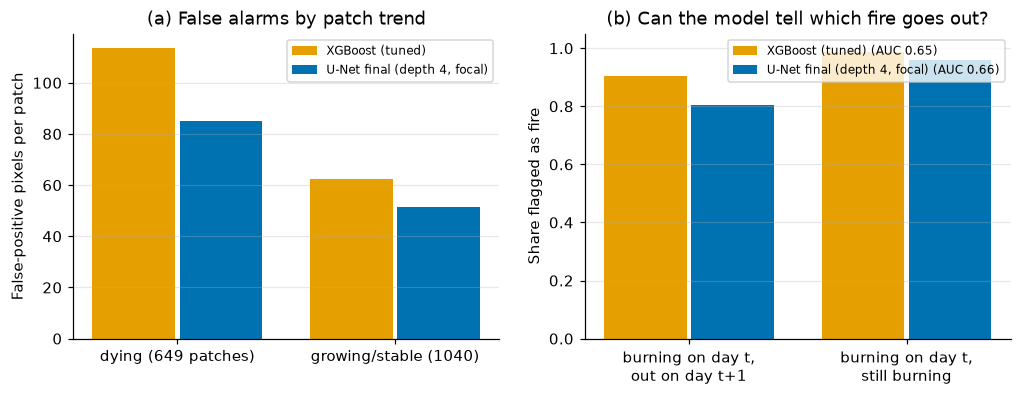

,XGBoost (tuned),"U-Net final (depth 4, focal)"
FP pixels (all),138714.000,108623.000
FP in dying patches,73665.000,55099.000
FP per dying patch,113.505,84.898
FP per growing patch,62.547,51.465
share of FP in dying patches,0.531,0.507
"mean score, 2 km halo, dying",0.915,0.707
"mean score, 2 km halo, growing",0.906,0.694
going-out pixels flagged,0.903,0.805
still-burning pixels flagged,0.988,0.958
ROC AUC still-burning vs going-out,0.646,0.661


In [11]:
fire_t = (prev == 1).sum(axis=(1, 2))
fire_t1 = (y_map == 1).sum(axis=(1, 2))
has_fire = fire_t > 0
dying = has_fire & (fire_t1 < fire_t)
growing = has_fire & ~dying
near = (dist > 0) & (dist <= 2) & (y_map == 0)                    # no-fire pixels in the 2 km halo
going_out, staying = (prev == 1) & (y_map == 0), (prev == 1) & (y_map == 1)
print(f"patches with day-t fire: {has_fire.sum()}, dying: {dying.sum()} ({dying[has_fire].mean():.0%}); "
      f"day-t fire pixels that go out: {going_out.sum():,} of {(prev == 1).sum():,}")

rows = {}
for m in HEAD:
    fp = eu.outcome_counts(y_map, PRED[m])["fp"]
    rows[MODELS[m]] = {
        "FP pixels (all)": int(fp.sum()),
        "FP in dying patches": int(fp[dying].sum()),
        "FP per dying patch": fp[dying].mean(),
        "FP per growing patch": fp[growing].mean(),
        "share of FP in dying patches": fp[dying].sum() / fp.sum(),
        "mean score, 2 km halo, dying": P[m][near & dying[:, None, None]].mean(),
        "mean score, 2 km halo, growing": P[m][near & growing[:, None, None]].mean(),
        "going-out pixels flagged": PRED[m][going_out].mean(),
        "still-burning pixels flagged": PRED[m][staying].mean(),
        "ROC AUC still-burning vs going-out": roc_auc_score(np.r_[np.ones(staying.sum()), np.zeros(going_out.sum())],
                                                            np.r_[P[m][staying], P[m][going_out]]),
    }
dying_table = pd.DataFrame(rows).T
dying_table.to_csv(DL_DIR / "dl_eval_dying_fires.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x, w = np.arange(2), 0.8 / len(HEAD)
for k, m in enumerate(HEAD):
    r = dying_table.loc[MODELS[m]]
    off = (k - (len(HEAD) - 1) / 2) * w
    axes[0].bar(x + off, [r["FP per dying patch"], r["FP per growing patch"]], w * 0.95, color=COLORS[m], label=MODELS[m])
    axes[1].bar(x + off, [r["going-out pixels flagged"], r["still-burning pixels flagged"]], w * 0.95, color=COLORS[m],
                label=f"{MODELS[m]} (AUC {r['ROC AUC still-burning vs going-out']:.2f})")
axes[0].set_xticks(x, [f"dying ({dying.sum()} patches)", f"growing/stable ({growing.sum()})"])
axes[0].set(ylabel="False-positive pixels per patch", title="(a) False alarms by patch trend")
axes[1].set_xticks(x, ["burning on day t,\nout on day t+1", "burning on day t,\nstill burning"])
axes[1].set(ylabel="Share flagged as fire", ylim=(0, 1.05), title="(b) Can the model tell which fire goes out?")
for ax in axes:
    ax.grid(axis="x", visible=False)
    ax.legend(fontsize=8)
fig.savefig(FIGS / "dl_eval_dying_fires.png")
plt.show()
dying_table.round(3).T

**Reading the dying-fire results**

- **Fewer false alarms, but not because the U-Net knows the fire is dying.** False positives fall from 138,714 to
  108,623 (−22%): by 25% in dying patches (113.5 → 84.9 per patch) and by 18% in growing ones (62.5 → 51.5). The
  share of false positives in dying patches barely moves (53.1% → 50.7%).
- Among pixels burning on day t, both models flag most of those that go out (XGBoost 90%, U-Net 81%), and neither
  can tell them from pixels that keep burning: ROC AUC 0.646 vs 0.661, close to the 0.5 of no skill. The U-Net's mean
  score in the 2 km halo is the same around dying and growing fires (0.707 vs 0.694).
- The halo is tighter, which cuts false alarms everywhere, but whether a fire dies down depends on information that is
  not in the inputs (fuel already burnt, suppression, next-day weather). This Phase 1 error is **reduced, not fixed**.

## 6 · Downwind check

`wind_sides` from notebook 02 (section 4c): for every day-t fire pixel, step 1-5 px downwind and upwind, keep pixels not
burning on day t, and compare the mean score on each side. The models' scores are on different scales, so panel (b)
compares the **ratio** downwind / upwind at 5 km by wind speed, next to the true next-day fire ratio in the same test
pixels. Phase 1 found that the data (train split) shows downwind spread growing with wind speed (5 km ratio 1.14 at
0-3 m/s to 3.1 at 8+ m/s; `reports/figures/eval_downwind_check.png`), but the test split is only 257 events and
does not show it at 3-8 m/s, so the train ratios are the reliable physical reference.

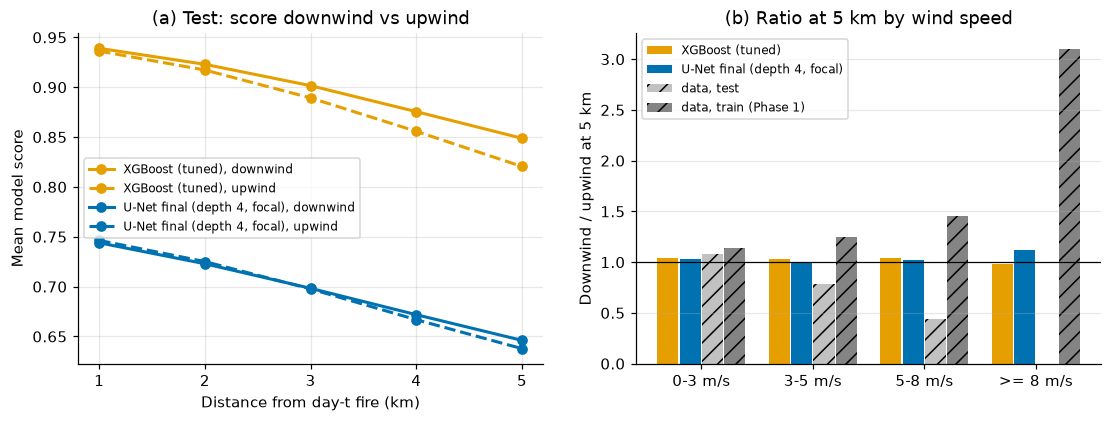

,wind_m/s,distance_px,side,pixels,true_fire_rate,xgboost,unet_final_s0
0,0-99,1,downwind,20657,0.1890,0.9390,0.7440
1,0-99,1,upwind,20749,0.2163,0.9362,0.7464
2,0-99,2,downwind,30848,0.1564,0.9230,0.7229
3,0-99,2,upwind,31102,0.1799,0.9172,0.7251
4,0-99,3,downwind,37369,0.1307,0.9016,0.6983
5,0-99,3,upwind,37790,0.1532,0.8893,0.6977
6,0-99,4,downwind,41668,0.1117,0.8755,0.6719
7,0-99,4,upwind,41963,0.1307,0.8558,0.6668
8,0-99,5,downwind,44392,0.0984,0.8488,0.6461
9,0-99,5,upwind,44821,0.1168,0.8205,0.6378


,xgboost,unet_final_s0,true_fire_rate,train data (Phase 1)
wind_m/s,,,,
0-3,1.041,1.028,1.081,1.135
3-5,1.031,1.005,0.782,1.250
5-8,1.039,1.022,0.444,1.457
8-99,0.986,1.124,NaN,3.100


In [12]:
BANDS = (0, 3, 5, 8, 99)
probs = {m: P[m] for m in HEAD}
wind_all = eu.wind_sides(prev, th_map, vs_map, y_map, probs)
wind_band = eu.wind_sides(prev, th_map, vs_map, y_map, probs, wind_bins=BANDS)
TRAIN_RATIO_5KM = {"0-3": 1.135, "3-5": 1.250, "5-8": 1.457, "8-99": 3.100}   # notebook 02 cell output, train split

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for m in HEAD:
    for side, ls in (("downwind", "-"), ("upwind", "--")):
        s = wind_all[wind_all["side"] == side]
        axes[0].plot(s["distance_px"], s[m], ls, marker="o", lw=2, color=COLORS[m], label=f"{MODELS[m]}, {side}")
axes[0].set(xlabel="Distance from day-t fire (km)", ylabel="Mean model score", xticks=range(1, 6),
            title="(a) Test: score downwind vs upwind")
axes[0].legend(fontsize=8)

s5 = wind_band[wind_band["distance_px"] == 5].pivot_table(index="wind_m/s", columns="side",
                                                          values=HEAD + ["true_fire_rate"], sort=False)
ratio = pd.DataFrame({k: s5[(k, "downwind")] / s5[(k, "upwind")] for k in HEAD + ["true_fire_rate"]})
ratio["train data (Phase 1)"] = pd.Series(TRAIN_RATIO_5KM)
x, series = np.arange(len(ratio)), HEAD + ["true_fire_rate", "train data (Phase 1)"]
w = 0.8 / len(series)
for k, col in enumerate(series):
    color = COLORS.get(col, "#999999" if col == "true_fire_rate" else "#333333")
    label = MODELS.get(col, "data, test" if col == "true_fire_rate" else "data, train (Phase 1)")
    axes[1].bar(x + (k - (len(series) - 1) / 2) * w, ratio[col], w * 0.95, color=color, label=label,
                hatch=None if col in MODELS else "//", alpha=1 if col in MODELS else 0.6)
axes[1].axhline(1, color="black", lw=0.8)
axes[1].set_xticks(x, [f"{b} m/s" if not b.endswith("99") else ">= 8 m/s" for b in ratio.index])
axes[1].set(ylabel="Downwind / upwind at 5 km", title="(b) Ratio at 5 km by wind speed")
axes[1].grid(axis="x", visible=False)
axes[1].legend(fontsize=8)
fig.savefig(FIGS / "dl_eval_downwind_check.png")
plt.show()
wind_all.to_csv(DL_DIR / "dl_eval_downwind.csv", index=False)
display(wind_all.round(4))
ratio.round(3)

**Reading the downwind check**

- **Neither model pushes risk clearly downwind.** At 5 km the downwind/upwind ratio of the score is 1.03 for XGBoost
  and 1.01 for the U-Net (all wind speeds); by wind band 1.03-1.04 for XGBoost and 1.00-1.03 for the U-Net, with
  1.12 above 8 m/s on few pixels. Neither ratio grows with wind speed as the training data does
  (1.14 → 3.1, Phase 1).
- Consistent with this, turning `th` with rotated patches changes nothing (Piyush's augmentation study, +0.001),
  and the U-Net's saliency is as large upwind as downwind (section 7). The U-Net, like XGBoost, does not make use of the wind direction.
- One reason: `th` is a daily GRIDMET value on a ≈4 km grid, almost constant over a patch, and the test split holds
  only 257 events with no labelled pixel at 8+ m/s; the downwind excess shows only on train.

## 7 · What does the U-Net look at? (the DL counterpart of Phase 1's SHAP)

Needs a checkpoint in `models/` (first of `CKPTS` found). The test inputs are normalised with the train-only statistics
in `reports/dl/norm_stats.json`; reloading the checkpoint must reproduce its official test PR AUC, which checks both.

**(a) Channel-group occlusion.** Set one group's channels to 0 (the train mean after normalisation) at inference and
re-score test. Groups as in `src/dl_data.CHANNEL_GROUPS`. This asks what the *trained* model uses; Sushant's ablation
retrains without the group and asks what information the *task* needs. Setting `PrevFireMask` to 0 means "no fire", so
the fire bar is large by construction.

**(b) Gradient saliency.** Gradient of the patch's summed predicted fire w.r.t. every input pixel and channel:
where would a small change of the input change the forecast most? Shown for 4 patches, then summarised over all
test patches by distance from the fire and by side of the wind (with `wind_sides`).

In [13]:
import torch

ckpt = next((c for c in CKPTS if (eu.MODELS_DIR / f"{c}.pt").exists()), None)
HAVE_MODEL = ckpt is not None
if not HAVE_MODEL:
    print(f"No checkpoint found ({', '.join(c + '.pt' for c in CKPTS)} in models/): section 7 is skipped.")
else:
    X_test = eu.test_inputs()
    model = eu.load_model(ckpt, **CKPTS[ckpt])
    p_ckpt = eu.predict(model, X_test)
    print(f"{ckpt}.pt on {eu.device()}: test PR AUC {eu.pr_auc(y_map, p_ckpt):.4f} "
          f"(official {results.loc[ckpt, 'pr_auc']:.4f})")
    if eu.pred_path(ckpt):
        print(f"max |difference| to the saved predictions: {np.abs(p_ckpt - eu.load_preds(ckpt)[1]).max():.2e}")

unet_final_s0.pt on mps: test PR AUC 0.3376 (official 0.3376)
max |difference| to the saved predictions: 1.94e-06


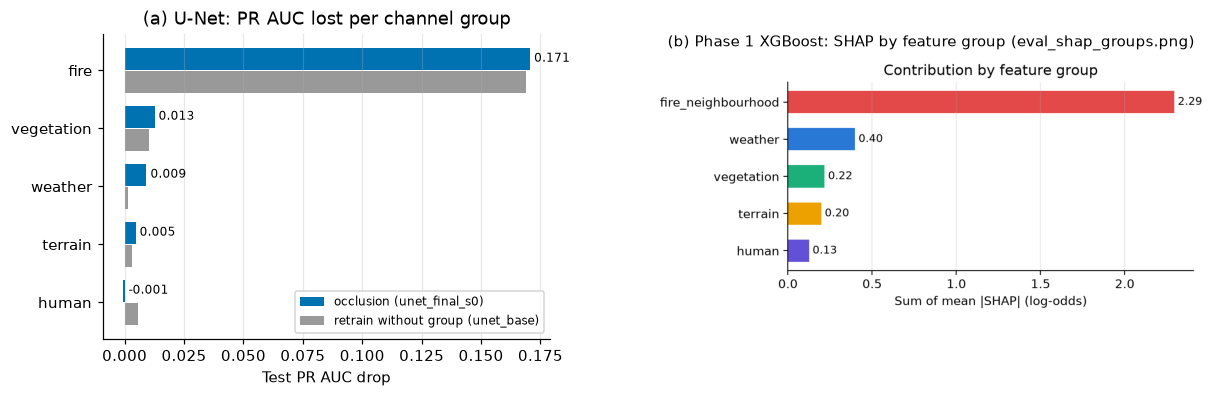

,channels,pr_auc,drop,retrain drop (Sushant),PR AUC far region
group,,,,,
none,,0.3376,0.0000,NaN,0.1537
weather,"th, vs, tmmn, tmmx, sph, pr, pdsi, erc",0.3284,0.0092,0.0016,0.1370
vegetation,NDVI,0.3250,0.0126,0.0103,0.1392
terrain,elevation,0.3330,0.0046,0.0032,0.1451
human,population,0.3383,-0.0007,0.0055,0.1537
fire,PrevFireMask,0.1670,0.1706,0.1688,0.1317


In [14]:
if HAVE_MODEL:
    occ = eu.occlusion(model, X_test, y_map, CHANNEL_GROUPS)
    abl = pd.read_csv(DL_DIR / "channel_ablation.csv").set_index("run")
    occ["retrain drop (Sushant)"] = [np.nan] + [abl.loc[f"unet_no_{g}", "pr_auc_drop"] for g in CHANNEL_GROUPS]
    # Same occlusion, scored only in the far region of section 4b (> 5 km from visible fire and from cloud)
    far_occ = {}
    for g, chans in {"none": [], **CHANNEL_GROUPS}.items():
        Xo = X_test.copy()
        if chans:
            Xo[:, [CHANNELS.index(c) for c in chans]] = 0
        far_occ[g] = average_precision_score(y_map[far_clear] == 1, eu.predict(model, Xo)[far_clear])
    occ["PR AUC far region"] = pd.Series(far_occ)
    occ.to_csv(DL_DIR / "dl_eval_occlusion.csv")

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.25]})
    o = occ.drop(index="none").sort_values("drop")
    yy = np.arange(len(o))
    axes[0].barh(yy + 0.2, o["drop"], 0.38, color=COLORS.get(ckpt, "#0072B2"), label=f"occlusion ({ckpt})")
    axes[0].barh(yy - 0.2, o["retrain drop (Sushant)"], 0.38, color="#999999", label="retrain without group (unet_base)")
    for k, v in enumerate(o["drop"]):
        axes[0].text(max(v, 0), k + 0.2, f" {v:.3f}", va="center", fontsize=8)
    axes[0].set_yticks(yy, o.index)
    axes[0].set(xlabel="Test PR AUC drop", title="(a) U-Net: PR AUC lost per channel group")
    axes[0].legend(fontsize=8, loc="lower right")
    axes[0].grid(axis="y", visible=False)
    axes[1].imshow(plt.imread("reports/figures/eval_shap_groups.png"))
    axes[1].axis("off")
    axes[1].set_title("(b) Phase 1 XGBoost: SHAP by feature group (eval_shap_groups.png)", fontsize=10)
    fig.savefig(FIGS / "dl_eval_occlusion_vs_shap.png")
    plt.show()
    display(occ.round(4))

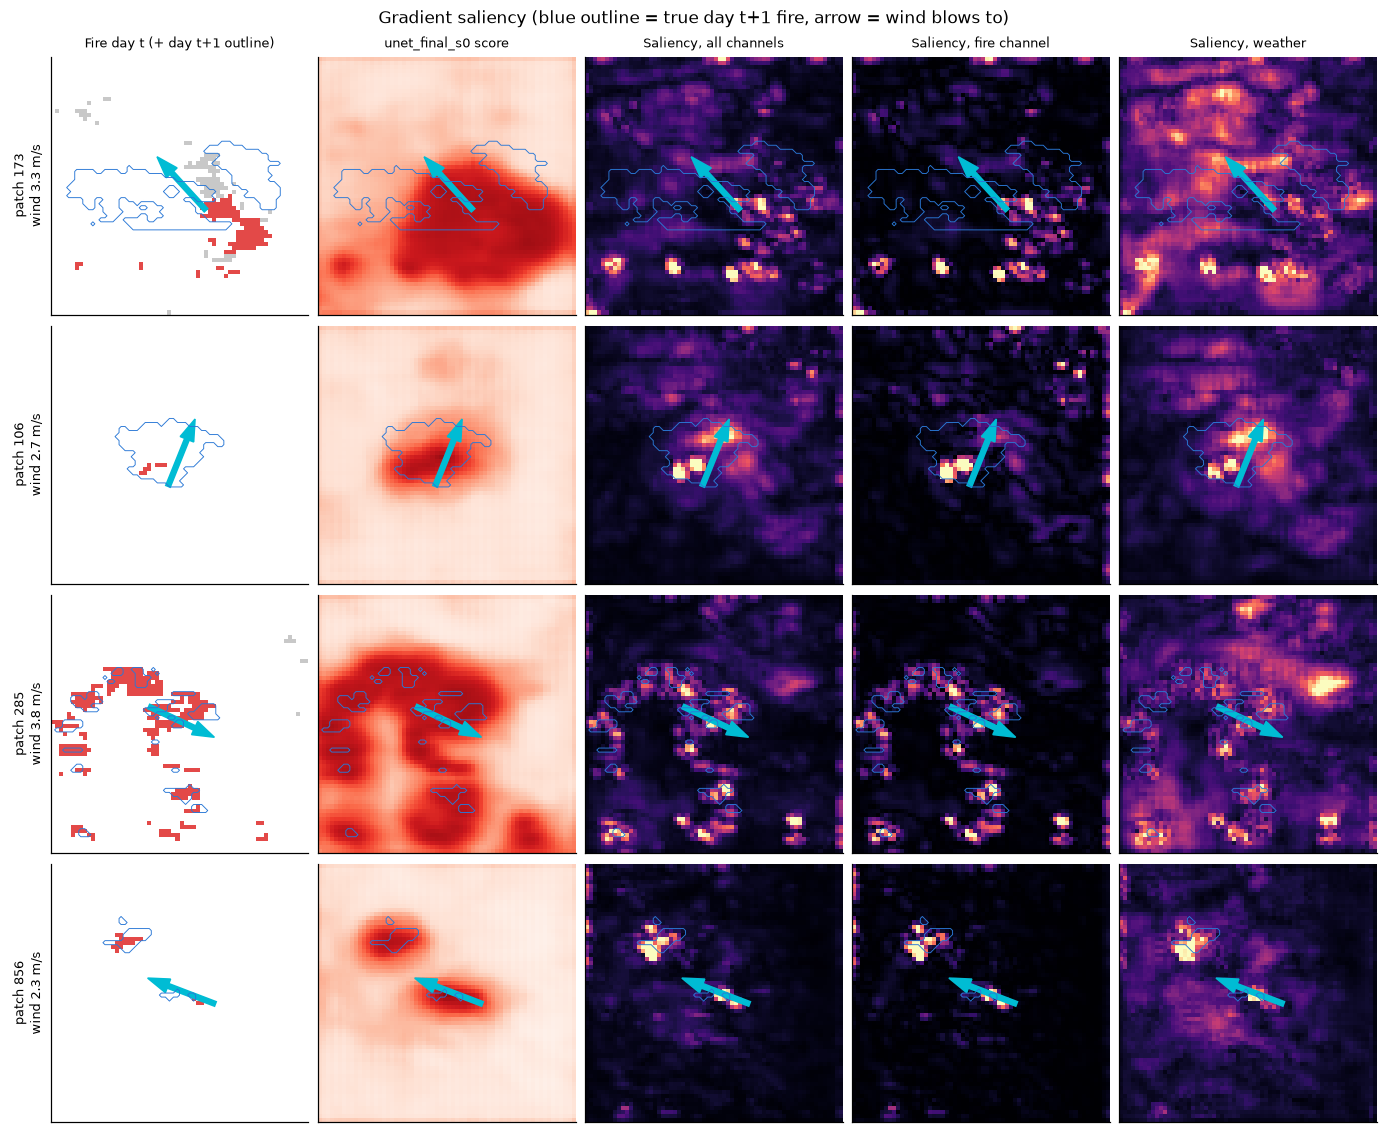

In [15]:
if HAVE_MODEL:
    GROUP_IDX = {g: [CHANNELS.index(c) for c in ch] for g, ch in CHANNEL_GROUPS.items()}
    # Saliency of every test patch with day-t fire, kept as maps per group: |gradient| summed over the group's channels
    sal = {g: np.zeros(y_map.shape, np.float32) for g in GROUP_IDX}
    idx_fire = np.flatnonzero(has_fire)
    for start in range(0, len(idx_fire), 32):
        b = idx_fire[start:start + 32]
        g_b = np.abs(eu.gradient_saliency(model, X_test, b))
        for g, ch in GROUP_IDX.items():
            sal[g][b] = g_b[:, ch].sum(axis=1)
    total = sum(sal.values())
    norm = total / np.maximum(total.sum(axis=(1, 2), keepdims=True), 1e-12)   # each patch sums to 1

    SAL_PATCHES = [173, 106, 285, 856]      # long jump, explosive growth, dying fire (Phase 1 cases) and a creeping fire
    fig, axes = plt.subplots(len(SAL_PATCHES), 5, figsize=(12.5, 2.55 * len(SAL_PATCHES)), layout="constrained")
    show = dict(interpolation="nearest", origin="lower")
    for r, i in enumerate(SAL_PATCHES):
        panels = [("Fire day t (+ day t+1 outline)", prev[i] + 1, MASK_CMAP, (0, 2)),
                  (f"{ckpt} score", p_ckpt[i], "Reds", (0, 1)),
                  ("Saliency, all channels", total[i], "magma", (0, np.percentile(total[i], 99.5))),
                  ("Saliency, fire channel", sal["fire"][i], "magma", (0, np.percentile(sal["fire"][i], 99.5))),
                  ("Saliency, weather", sal["weather"][i], "magma", (0, np.percentile(sal["weather"][i], 99.5)))]
        for ax, (t, img, cmap, (lo, hi)) in zip(axes[r], panels):
            ax.imshow(img, cmap=cmap, vmin=lo, vmax=max(hi, 1e-12), **show)
            if (y_map[i] == 1).any():
                ax.contour(y_map[i] == 1, levels=[0.5], colors="#2a78d6", linewidths=0.6)
            eu.wind_arrow(ax, th_map[i], color="#00bcd4")
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            if r == 0:
                ax.set_title(t, fontsize=8.5)
        axes[r, 0].set_ylabel(f"patch {i}\nwind {vs_map[i].mean():.1f} m/s", fontsize=8.5)
    fig.suptitle("Gradient saliency (blue outline = true day t+1 fire, arrow = wind blows to)", fontsize=11)
    fig.savefig(FIGS / "dl_eval_saliency_maps.png")
    plt.show()

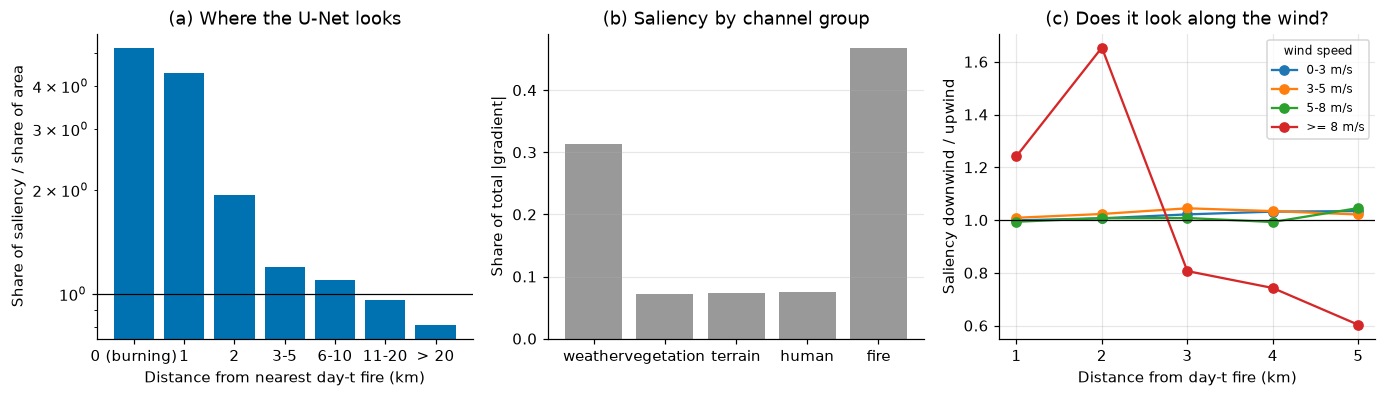

,share of saliency,share of area,saliency / area
0 (burning),0.0487,0.0094,5.1684
1,0.0605,0.0139,4.3662
2,0.0244,0.0126,1.9394
3-5,0.0501,0.0419,1.1960
6-10,0.1118,0.1019,1.0972
11-20,0.2434,0.2541,0.9578
> 20,0.4612,0.5663,0.8143


weather       0.3132
vegetation    0.0720
terrain       0.0731
human         0.0743
fire          0.4675
dtype: float32

side                  downwind  upwind  down/up
wind_m/s distance_px                           
0-3      1               0.001   0.001    0.999
         2               0.001   0.001    1.007
         3               0.000   0.000    1.021
         4               0.000   0.000    1.032
         5               0.000   0.000    1.034
3-5      1               0.001   0.001    1.009
         2               0.001   0.001    1.023
         3               0.001   0.000    1.045
         4               0.000   0.000    1.034
         5               0.000   0.000    1.021
5-8      1               0.002   0.002    0.994
         2               0.001   0.001    1.007
         3               0.001   0.001    1.008
         4               0.000   0.000    0.993
         5               0.000   0.000    1.045
8-99     1               0.005   0.004    1.242
         2               0.002   0.001    1.654
         3               0.000   0.000    0.807
         4               0.000   0.000    0.742
         5               0.000   0.000    0.603

In [16]:
if HAVE_MODEL:
    # Where is the saliency? Share per distance band (each patch weighted equally), and per channel group.
    d_fire = dist[has_fire]
    band_px = pd.cut(d_fire.ravel(), eu.DIST_BINS, labels=eu.DIST_NAMES, include_lowest=True)
    by_band = pd.DataFrame({
        "share of saliency": pd.Series(norm[has_fire].ravel()).groupby(band_px, observed=False).sum() / has_fire.sum(),
        "share of area": pd.Series(np.ones(band_px.size)).groupby(band_px, observed=False).sum() / band_px.size,
    })
    by_band["saliency / area"] = by_band["share of saliency"] / by_band["share of area"]
    group_share = pd.Series({g: sal[g][has_fire].sum() for g in sal}) / total[has_fire].sum()

    # Does it look along the wind? Mean normalised saliency downwind vs upwind of the day-t fire (wind_sides).
    sal_wind = eu.wind_sides(prev, th_map, vs_map, y_map, {"saliency": norm}, wind_bins=BANDS)
    sal_ratio = sal_wind.pivot_table(index=["wind_m/s", "distance_px"], columns="side", values="saliency", sort=False)
    sal_ratio["down/up"] = sal_ratio["downwind"] / sal_ratio["upwind"]

    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
    axes[0].bar(by_band.index.astype(str), by_band["saliency / area"], color=COLORS.get(ckpt, "#0072B2"))
    axes[0].axhline(1, color="black", lw=0.8)
    axes[0].set(xlabel="Distance from nearest day-t fire (km)", ylabel="Share of saliency / share of area",
                yscale="log", title="(a) Where the U-Net looks")
    axes[1].bar(group_share.index, group_share.values, color="#999999")
    axes[1].set(ylabel="Share of total |gradient|", title="(b) Saliency by channel group")
    for b in [b for b in sal_ratio.index.get_level_values(0).unique() if sal_ratio.loc[b]["upwind"].notna().all()]:
        s = sal_ratio.loc[b]
        axes[2].plot(s.index, s["down/up"], "o-", label=f"{b} m/s" if not b.endswith("99") else ">= 8 m/s")
    axes[2].axhline(1, color="black", lw=0.8)
    axes[2].set(xlabel="Distance from day-t fire (km)", ylabel="Saliency downwind / upwind", xticks=range(1, 6),
                title="(c) Does it look along the wind?")
    axes[2].legend(fontsize=8, title="wind speed", title_fontsize=8)
    for ax in axes[:2]:
        ax.grid(axis="x", visible=False)
    fig.savefig(FIGS / "dl_eval_saliency_summary.png")
    plt.show()
    display(by_band.round(4), group_share.round(4), sal_ratio.round(3))

**Reading the saliency results**

- **Both phases rely on the same thing: where the fire is now.** Blanking `PrevFireMask` costs 0.171 PR AUC, the
  same as Sushant's retraining without it (0.169), and the fire group carries 47% of the gradient saliency. In
  Phase 1, SHAP gave the fire-neighbourhood features 2.29 log-odds against 0.40 for all weather.
- The trained U-Net uses vegetation (0.013) and weather (0.009) a little more than retraining suggests
  (0.010, 0.002): a network retrained without them compensates from the other channels. Population is not used.
  Weather holds 31% of the saliency but changes PR AUC little, a large but diffuse sensitivity.
- **It looks beyond the front, mostly near it.** Relative to area, saliency is 5.2× above average on burning pixels,
  4.4× at 1 km, 1.9× at 2 km, ≈1.1-1.2× at 3-10 km and 0.8× beyond 20 km. The maps show it concentrated on the
  edges of the day-t fire. In patch 173 the fire's 30 km run to the west gets almost none, the case it misses.
- **It does not look along the wind**: saliency downwind / upwind is 1.00-1.05 at every distance below 8 m/s.

## 8 · Event-level scores

Test patches grouped into fire events exactly as in notebook 02 (crops of the same place, matched on 16 × 16 elevation
blocks); each event counts once. Intervals for the pooled PR AUC are Priyanshu's (`reports/dl/checks/ci_events.csv`
and `ci_diffs_seeds_vs_xgboost.csv`, 1,000 event resamples); they are cited, not recomputed. His XGBoost is a refit
with the committed hyperparameters (0.2576 against the committed 0.2565), so his paired differences are ≈0.001 smaller
than against the committed model. The interval for the **mean over events** is new and computed here, resampling the
scored events with seed 0.

257 events, 240 scored; small event = at most 36 next-day fire pixels


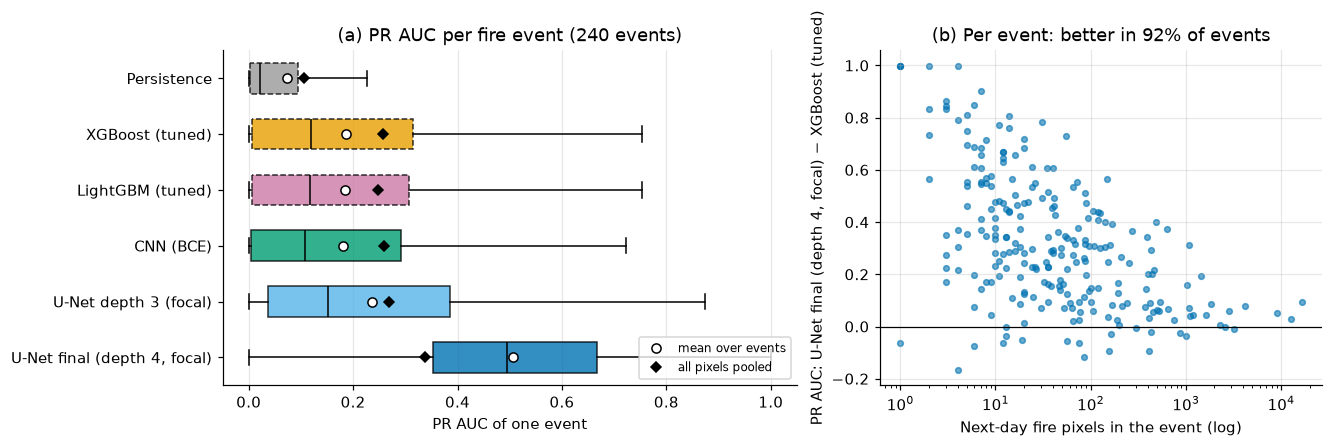

,pr_auc,lo95,hi95
model,,,
unet_final_s0,0.3376,0.2928,0.3854
cnn_bce,0.2591,0.1801,0.3334
xgboost,0.2576,0.1900,0.3220
persistence,0.1065,0.0591,0.1611


,a,b,diff,lo95,hi95,share_a_better
0,unet_final_s0,xgboost,0.0800,0.0577,0.1131,1.000
1,unet_final_s0,persistence,0.2311,0.2145,0.2573,1.000
2,cnn_bce,xgboost,0.0014,-0.0113,0.0133,0.572
3,cnn_bce,persistence,0.1525,0.1204,0.1748,1.000
4,unet_final_s0,cnn_bce,0.0785,0.0491,0.1210,1.000


,PR AUC (pixels pooled),PR AUC (mean over events),PR AUC (median over events),PR AUC (small events),PR AUC (large events),Recall (mean over events),Events with any fire found
Model,,,,,,,
Persistence,0.106,0.074,0.021,0.074,0.074,0.154,0.608
XGBoost (tuned),0.256,0.187,0.120,0.157,0.219,0.246,0.479
LightGBM (tuned),0.248,0.184,0.116,0.160,0.210,0.250,0.512
CNN (BCE),0.259,0.180,0.108,0.161,0.201,0.238,0.525
U-Net depth 3 (focal),0.269,0.236,0.152,0.225,0.247,0.319,0.600
"U-Net final (depth 4, focal)",0.338,0.506,0.494,0.587,0.419,0.635,0.988


In [17]:
event_of = eu.group_events(maps["elev"])
per_event = {m: eu.event_scores(y_map, P[m], THR[m], event_of) for m in MODELS}
median_fire = per_event[REF_P1]["fire_px"].median()
event_table = pd.DataFrame({MODELS[m]: eu.event_summary(s, results.loc[m, "pr_auc"], median_fire)
                            for m, s in per_event.items()}).T
event_table.index.name = "Model"
print(f"{len(set(event_of))} events, {len(per_event[REF_P1])} scored; small event = at most {median_fire:.0f} next-day fire pixels")

ci = pd.read_csv(DL_DIR / "checks" / "ci_events.csv").set_index("model")
ci_diff = pd.read_csv(DL_DIR / "checks" / "ci_diffs_events.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.3, 1]}, layout="constrained")
names = list(MODELS)
pos = np.arange(1, len(names) + 1)
bp = axes[0].boxplot([per_event[m]["pr_auc"] for m in names], positions=pos, orientation="horizontal", widths=0.55,
                     patch_artist=True, showfliers=False, medianprops={"color": "black"})
for box, m in zip(bp["boxes"], names):
    box.set(facecolor=COLORS[m], alpha=0.8, linestyle=STYLE[m])
axes[0].plot([per_event[m]["pr_auc"].mean() for m in names], pos, "o", color="white", mec="black", ms=6, label="mean over events")
axes[0].plot(results.loc[names, "pr_auc"], pos, "D", color="black", ms=5, label="all pixels pooled")
axes[0].set_yticks(pos, [MODELS[m] for m in names])
axes[0].invert_yaxis()
axes[0].set(xlabel="PR AUC of one event", title=f"(a) PR AUC per fire event ({len(per_event[REF_P1])} events)")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].grid(axis="y", visible=False)
if len(HEAD) == 2:      # paired: same events, U-Net minus XGBoost
    a, b = per_event[REF_P2]["pr_auc"].align(per_event[REF_P1]["pr_auc"], join="inner")
    axes[1].scatter(per_event[REF_P1].loc[a.index, "fire_px"], a - b, s=14, alpha=0.6, color=COLORS[REF_P2])
    axes[1].axhline(0, color="black", lw=0.8)
    axes[1].set(xscale="log", xlabel="Next-day fire pixels in the event (log)",
                ylabel=f"PR AUC: {MODELS[REF_P2]} − {MODELS[REF_P1]}",
                title=f"(b) Per event: better in {(a > b).mean():.0%} of events")
fig.savefig(FIGS / "dl_eval_event_level.png")
plt.show()
display(ci.round(4), ci_diff.round(4))
event_table.round(3)

In [18]:
ci_seeds = pd.read_csv(DL_DIR / "checks" / "ci_diffs_seeds_vs_xgboost.csv")   # Priyanshu: paired, per seed
FINAL_SEEDS = [m for m in ["unet_final_s0", "unet_final_s1", "unet_final_s2"] if eu.pred_path(m)]

# Mean PR AUC over events (each event counts once): resample the scored events, same seed
ev_ids = per_event[REF_P1].index
rng = np.random.default_rng(SEED)
draws = rng.integers(0, len(ev_ids), size=(1000, len(ev_ids)))
ev_rows = []
for m in [REF_P1] + FINAL_SEEDS:
    s = eu.event_scores(y_map, P[m] if m in P else eu.load_preds(m)[1],
                        results.loc[m, "threshold"], event_of)["pr_auc"].reindex(ev_ids).to_numpy()
    ev_rows.append((m, s))
ref = dict(ev_rows)[REF_P1]
ev_ci = pd.DataFrame([{"model": m, "mean over events": s.mean(), "lo95": np.percentile(s[draws].mean(1), 2.5),
                       "hi95": np.percentile(s[draws].mean(1), 97.5),
                       f"diff vs {REF_P1}": (s - ref).mean(),
                       "diff lo95": np.percentile((s - ref)[draws].mean(1), 2.5),
                       "diff hi95": np.percentile((s - ref)[draws].mean(1), 97.5),
                       "events better": ((s - ref) > 0).mean()} for m, s in ev_rows]).set_index("model")
ev_ci.to_csv(DL_DIR / "dl_eval_ci_event_mean.csv")
display(ci_seeds.round(4))
ev_ci.round(3)

,a,b,diff,lo95,hi95,share_a_better
0,unet_final_s0,xgboost,0.0800,0.0577,0.1131,1.000
1,unet_final_s1,xgboost,0.0853,0.0586,0.1221,1.000
2,unet_final_s2,xgboost,0.0938,0.0777,0.1176,1.000
3,cnn_bce,xgboost,0.0014,-0.0113,0.0133,0.572
4,cnn_bce_s1,xgboost,-0.0093,-0.0222,0.0050,0.115
5,cnn_bce_s2,xgboost,-0.0183,-0.0294,-0.0080,0.001


,mean over events,lo95,hi95,diff vs xgboost,diff lo95,diff hi95,events better
model,,,,,,,
xgboost,0.187,0.161,0.215,0.000,0.000,0.000,0.000
unet_final_s0,0.506,0.480,0.535,0.318,0.288,0.352,0.921
unet_final_s1,0.510,0.483,0.537,0.322,0.292,0.354,0.929
unet_final_s2,0.493,0.465,0.522,0.305,0.274,0.338,0.929


In [19]:
md_event = "\n".join([
    "## Event-level evaluation",
    "",
    f"Test patches grouped into {len(set(event_of))} events (crops of the same place, matched on elevation, as in Phase 1); "
    f"{len(per_event[REF_P1])} events have both fire and no-fire pixels and are scored. Each event counts once. "
    f"Small event = at most {median_fire:.0f} next-day fire pixels. Recall at the eval-chosen threshold. Seed-0 runs. Bold = best per column.",
    "",
    eu.to_markdown(event_table),
    "",
    "95% intervals over fire events (Priyanshu, `reports/dl/checks/ci_events.csv`, 1,000 resamples; his XGBoost row is a refit, 0.2576):",
    "",
    eu.to_markdown(ci.rename(columns={"pr_auc": "PR AUC", "lo95": "2.5%", "hi95": "97.5%"}).rename_axis("Model"),
                   fmt="{:.4f}", bold_max=False),
    "",
    "Paired difference against XGBoost on the same resamples (Priyanshu, `ci_diffs_seeds_vs_xgboost.csv`):",
    "",
    eu.to_markdown(ci_seeds.set_index("a").rename_axis("Model"), fmt="{:.4f}", bold_max=False),
    "",
    "Mean PR AUC over events (each event once), events resampled:",
    "",
    eu.to_markdown(ev_ci.rename_axis("Model"), fmt="{:.3f}", bold_max=False),
    "",
])
(DL_DIR / "results_table.md").write_text(md_main + "\n" + md_event)
print("wrote", DL_DIR / "results_table.md")

wrote reports/dl/results_table.md


**Reading the event-level scores**

- **Per event the gap is much larger than pooled.** Mean PR AUC over the 240 events: 0.506 [0.480, 0.535] for the
  final U-Net against 0.187 [0.161, 0.215] for XGBoost; paired difference +0.318 [0.288, 0.352], better in 92% of
  events. The other seeds agree (+0.322, +0.305). Pooled pixels, which a few large fires dominate, give
  +0.080 [0.058, 0.113] (Priyanshu's interval).
- The gain is largest on **small fires** (≤ 36 next-day fire pixels): 0.587 vs 0.157, and large ones 0.419 vs 0.219.
  A small fire gives a pixel model little neighbourhood signal, while the U-Net sees the whole patch.
- At the eval threshold the U-Net finds fire in 98.8% of events (XGBoost 47.9%, persistence 60.8%), so Phase 1's
  problem that the pooled-F1 threshold misses small fires is gone.
- The depth-3 U-Net and the CNN stay close to XGBoost (0.236 and 0.180): again, depth 4 is the step that matters.

## 9 · Summary: did seeing the whole patch fix Phase 1's errors?


| Phase 1 error | XGBoost | Final U-Net | Verdict |
|---|---:|---:|---|
| Recall of fire 3-5 km from the front | 0.044 | 0.331 | improved |
| Recall of fire beyond 5 km | 0.000 | 0.195 | **partly fixed** |
| Missed fire lying beyond 5 km | 64.4% | 56.8% | still most misses |
| False positives per dying patch | 113.5 | 84.9 | reduced (−25%) |
| Telling dying from burning pixels (ROC AUC) | 0.646 | 0.661 | **not fixed** |
| Downwind / upwind score at 5 km | 1.03 | 1.01 | neither follows the wind |
| Mean PR AUC over events | 0.187 | 0.506 | improved (+0.318 [0.288, 0.352]) |

Seeing the whole patch fixes part of the first error: the depth-4 U-Net predicts a fifth of the fire beyond 5 km,
where Phase 1 found none, and the gain survives checks for memorised locations, hidden fire and patch-level
shortcuts. It reduces the second error only through a tighter halo; it still cannot tell which fire is dying, and,
like Phase 1, it makes little use of the wind direction. Both remaining errors point to information missing from a
single day of inputs (burnt fuel, suppression, next-day weather) rather than to the model.